In [1]:
import torch
from torch import nn
from sklearn import model_selection
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from IPython import display
import numpy as np

from pathlib import Path
import json

import typing
%matplotlib inline

[HAMI-core Msg(6540:139641595927872:libvgpu.c:839)]: Initializing.....


<b>Part 0 — Setup: data and computing </b>

In [2]:
for folder in ["configs", "splits", "src", "results", "figures", "scripts"]:
    Path(folder).mkdir(exist_ok=True)

<b> 0.1 - Fixed data partitions</b>

In [3]:
# using PyTorch to get the training dataset
from torchvision.datasets import FashionMNIST
train_dataset = FashionMNIST(root="data",train=True,download=True,)

100%|██████████| 26.4M/26.4M [00:00<00:00, 117MB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 2.27MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 33.9MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.9MB/s]


In [4]:
#quick check of the dataset
train_dataset

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train

In [5]:
# Extracting the contents from this downloaded dataset above
x_data = train_dataset.data
y_target = train_dataset.targets
print(x_data.shape)
print(y_target.shape)

torch.Size([60000, 28, 28])
torch.Size([60000])


In [6]:
#Another way of doing this from the google search, this gives numpy arrays directly to be used below
images = train_dataset.data.numpy()
classes = train_dataset.targets.numpy()
class_names = train_dataset.classes

<b> **  Understanding the dataset  ** </b>

In [7]:
print("total samples", len(train_dataset))
print("images, i.e., X/data", images.shape)
print("the labels for them, i.e., Y/target", classes.shape)
print("the 10 classes:", class_names)

total samples 60000
images, i.e., X/data (60000, 28, 28)
the labels for them, i.e., Y/target (60000,)
the 10 classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [8]:
# Check the distribution of images across the classes
unique_labels, counts = torch.unique(y_target, return_counts=True)
for label_index, count in zip(unique_labels, counts):
    class_name = class_names[label_index.item()]
    print(f"{class_name}: {count.item()} images")

T-shirt/top: 6000 images
Trouser: 6000 images
Pullover: 6000 images
Dress: 6000 images
Coat: 6000 images
Sandal: 6000 images
Shirt: 6000 images
Sneaker: 6000 images
Bag: 6000 images
Ankle boot: 6000 images


In [9]:
# Grab a random sample from the dataset to see how it looks
img, cls = train_dataset[9]
print(f"Image datatype: {type(img)}")
print(f"Class datatype: {type(cls)}")
print(f"Class: {cls}: Class name: {class_names[cls]}")
print("image range:", images.min(), "to", images.max())

Image datatype: <class 'PIL.Image.Image'>
Class datatype: <class 'int'>
Class: 5: Class name: Sandal
image range: 0 to 255


In [10]:
#from sklearn.model_selection import StratifiedShuffleSplit
#import numpy as np
#TEST_SEED = 42
#the stratified splitter per documentation 
#strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=10000, random_state=TEST_SEED)
#targets = np.array(train_dataset.targets)
#train_index, val_index = next(strat_shuff_split.split(np.zeros(len(targets)), targets))

In [11]:
#official training set, stratified and seeded: 50,000 train / 10,000 validation stratified by class
#this is better way of stratification so commenting above method but keeping as backup if needed
from sklearn.model_selection import train_test_split

TEST_SEED = 42 #validation set
FIT_SEED = 43  #fitting set

all_index = np.arange(len(classes))
train_index, val_index = train_test_split(
    all_index,train_size=50_000,test_size=10_000,random_state=TEST_SEED,stratify=classes,)

#fixed stratified 10,000-image subset of the training partition for fitting
fit_index, _ = train_test_split(
    train_index,train_size=10_000,random_state=FIT_SEED,stratify=classes[train_index],)

In [12]:
#saving the seeds and index
split_config = {
    "test_seed": TEST_SEED,
    "fit_seed": FIT_SEED,
    "train_index": train_index.tolist(),
    "val_index": val_index.tolist(),
    "fit_index":fit_index.tolist()
}
with open("configs/fashion_mnist_split_config.json", "w") as f:
    json.dump(split_config, f)

In [13]:
#check that split and stratification worked correctly
print(f"training set size: {len(train_index)}")
print(f"validation set size: {len(val_index)}")
print(f"fit set size: {len(fit_index)}")

class_counts = pd.DataFrame(
    {
        "training set": np.bincount(classes[train_index]),
        "fitting subset": np.bincount(classes[fit_index]),
        "testing set": np.bincount(classes[val_index]),
    },index=pd.Index(class_names, name="Class"),)
print(class_counts.to_string())


training set size: 50000
validation set size: 10000
fit set size: 10000
             training set  fitting subset  testing set
Class                                                 
T-shirt/top          5000            1000         1000
Trouser              5000            1000         1000
Pullover             5000            1000         1000
Dress                5000            1000         1000
Coat                 5000            1000         1000
Sandal               5000            1000         1000
Shirt                5000            1000         1000
Sneaker              5000            1000         1000
Bag                  5000            1000         1000
Ankle boot           5000            1000         1000


In [14]:
#converting image values to float32 and divided by 255 to scale it from 0 to 1
# standardizing the fitting subset of the training
X_fit = images[fit_index].astype(np.float32).reshape(len(fit_index), -1) / 255.0
y_fit = classes[fit_index]

# standardizing the validation subset
X_val = images[val_index].astype(np.float32).reshape(len(val_index), -1) / 255.0
y_val = classes[val_index]

In [15]:
#checking that the standardization worked
print("fitting images:", X_fit.shape, X_fit.dtype)
print("fitting classes:", y_fit.shape, y_fit.dtype)
print("validation images:", X_val.shape, X_val.dtype)
print("validation classes:", y_val.shape, y_val.dtype)
print("fitting pixel range:", X_fit.min(), "to", X_fit.max())

fitting images: (10000, 784) float32
fitting classes: (10000,) int64
validation images: (10000, 784) float32
validation classes: (10000,) int64
fitting pixel range: 0.0 to 1.0


In [16]:
#cluster subsets for training and validation
CLUSTER_SEED = 44
cluster_train_index, _ = train_test_split(fit_index, train_size=3_000,
    random_state=CLUSTER_SEED,stratify=classes[fit_index])
cluster_val_index, _ = train_test_split(val_index, train_size=1_000,
    random_state=CLUSTER_SEED,stratify=classes[val_index])

# Taking labels from test set only to create the required stratified test subset.
# This is allowed per the coursework instructions
test_dataset = FashionMNIST(root="data",train=False,download=True,)
test_classes = test_dataset.targets.numpy()
test_index = np.arange(len(test_classes))

cluster_test_index, _ = train_test_split(test_index, train_size=1_000,
    random_state=CLUSTER_SEED,stratify=test_classes[test_index])

In [17]:
# write this as well to a seperate config file
cluster_config = {
    "cluster_seed": CLUSTER_SEED,
    "train_index": cluster_train_index.tolist(),
    "val_index": cluster_val_index.tolist(),
    "test_index":cluster_test_index.tolist()
}
with open("configs/fashion_mnist_cluster_config.json", "w") as f:
    json.dump(cluster_config, f)

In [18]:
#checking that the clustering worked correctly
print(f"Clustering train size: {len(cluster_train_index)}")      # must be: 3000
print(f"Clustering val size:   {len(cluster_val_index)}")        # must be: 1000
print(f"Clustering test size:  {len(cluster_test_index)}")  
cluster_summary = pd.DataFrame({
    "Subset": ["Training", "Validation", "Test"],
    "Images": [len(cluster_train_index),len(cluster_val_index),len(cluster_test_index),],
    "Images per class": [300, 100, 100],})

#print(cluster_summary.to_string())
print(cluster_summary.to_string(index=False))

Clustering train size: 3000
Clustering val size:   1000
Clustering test size:  1000
    Subset  Images  Images per class
  Training    3000               300
Validation    1000               100
      Test    1000               100


In [19]:
#R3. Keep an experiment register. Per experiment: ID, question, hypothesis, changed variable, fixed conditions, split, seed, configuration, metric, result, output path. Keep informative failures.
#note: not sure if its needed for Part 0, but creating one anyway as a template for later use

register_path = Path("results/experiment_register.csv")
exp_data_setup = {
    "id": "P0-DATA_SETUP-01",
    "question": "Are the data partitions stratified, seeded and saved so they are reproducible?",
    "hypothesis": "Class proportions are preserved by stratification",
    "changed_variable": "Nothing so far",
    "fixed_conditions": "Fashion-MNIST dataset downloaded",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": " 28 x 28 float32 pixels / 0-255, flattened to 784 features",
    "metric": "set sizes, class counts, index overlap",
    "result": (
        f"Train/validation overlap = {np.intersect1d(train_index, val_index).size}; "
        f"clustering sizes={len(cluster_train_index)}/{len(cluster_val_index)}/{len(cluster_test_index)}"
    ),
    "output_path": (
        "configs/fashion_mnist_split_config.json; configs/cashion_mnist_cluster_config.json; "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_data_setup])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

<b>Part 1 — Classical classification</b>

<b> 1.1 - My plan </b> - Instead of directly chosing  two classifiers, I am trying out and learning four, will perform accuracy, error analysis on all and will finally chose two and justify<br>
<b> 1.2 - My plan </b> - All four will ahve overall accuracy and class-level view of performance.It also makes it easy for me to compare and chose.

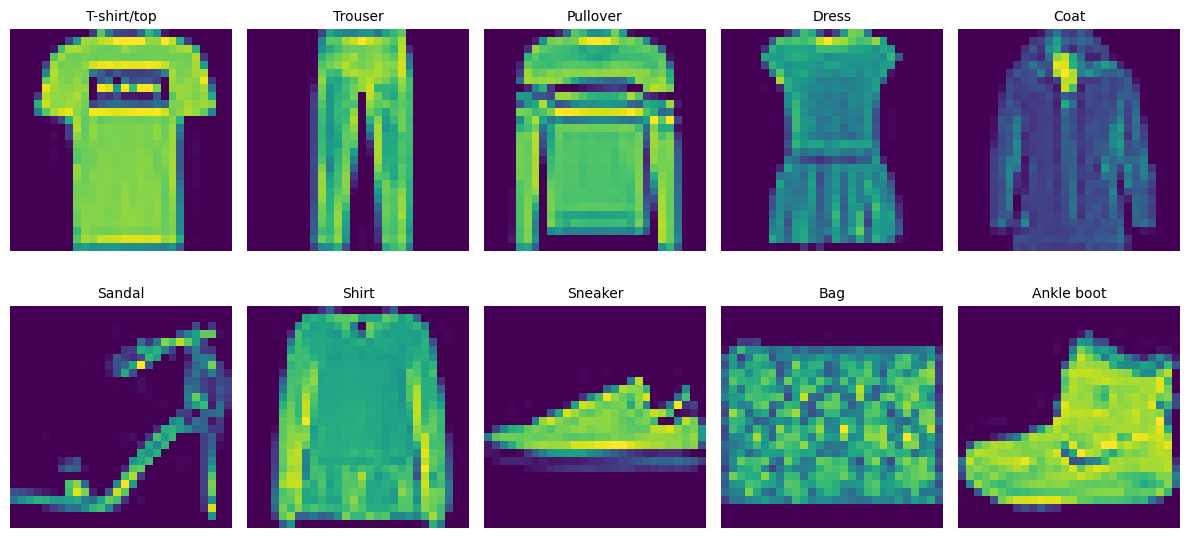

In [20]:
#Visualizing 1 examples each forall class types to understand the data
#dictionary to hold one index per class
class_indices = {}
# finding one example for every class
for index, label in enumerate(train_dataset.targets):
    label_item = label.item() if hasattr(label, 'item') else int(label)
    if label_item not in class_indices:
        class_indices[label_item] = index
    if len(class_indices) == 10:
        break

# 2x5 grid plot
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

# Plot each class example
for i in range(10):
    img_index= class_indices[i]
    img, label = train_dataset[img_index]
    img_array = np.array(img)
    axes[i].imshow(img_array)
#    axes[i].imshow(img_array, cmap='gray')
    axes[i].set_title(train_dataset.classes[i], fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [22]:
# Part 1.1 - Instead of choosing two, trying some classifiers first to learn how they all differ
# To-do: I have to choose two eventually and justity
# This is for trying out and learning Logistic Regression
from sklearn.linear_model import LogisticRegression
register_path = Path("results/experiment_register.csv")
logreg = LogisticRegression(C=1.0, solver="lbfgs", max_iter=500)
logreg.fit(X_fit, y_fit)
fit_predict_logreg = logreg.predict(X_fit)
val_predict_logreg = logreg.predict(X_val)

print(f"Logistic Regression: fitting accuracy: {accuracy_score(y_fit, fit_predict_logreg):.2%}")
print(f"Logistic Regression: validation accuracy: {accuracy_score(y_val, val_predict_logreg):.2%}")

cm = confusion_matrix(y_val, val_predict_logreg, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Logistic Rregression: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_lr = pd.DataFrame(classification_report(y_val, val_predict_logreg,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_lr = report_lr.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_lr["support"] = class_level_lr["support"].astype(int)
class_level_lr.to_csv("results/part1_2_logreg_validation_by_class.csv")
print(class_level_lr.round(3).to_string())

exp_part1_logreg = {"id": "P1-LOGREG-01",
    "question": "Is Logistic Regression the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "C=1.0, solver=lbfgs, max_iter=500",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "C=1.0, solver=lbfgs, max_iter=500",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (f"fit accuracy: {accuracy_score(y_fit, fit_predict_logreg):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_logreg):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"),
    "output_path": ("results/part1_2_logreg_validation_by_class.csv "),}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Logistic Regression: fitting accuracy: 92.46%
Logistic Regression: validation accuracy: 84.08%
Logistic Rregression: Lowest recall = 59.6% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.784   0.813     0.798     1000
Trouser          0.968   0.961     0.964     1000
Pullover         0.731   0.743     0.737     1000
Dress            0.864   0.829     0.846     1000
Coat             0.727   0.741     0.734     1000
Sandal           0.931   0.924     0.928     1000
Shirt            0.616   0.596     0.606     1000
Sneaker          0.908   0.909     0.909     1000
Bag              0.947   0.940     0.943     1000
Ankle boot       0.933   0.952     0.943     1000


In [23]:
print(class_level_lr.sort_values("recall")[["recall", "support"]].to_string())

             recall  support
Shirt         0.596     1000
Coat          0.741     1000
Pullover      0.743     1000
T-shirt/top   0.813     1000
Dress         0.829     1000
Sneaker       0.909     1000
Sandal        0.924     1000
Bag           0.940     1000
Ankle boot    0.952     1000
Trouser       0.961     1000


In [24]:
# my analysis: shirt was hardest (25.4% of errors) / Trouser was easiest
# my analysis: what did the model predict incorrectly for those 404 missed shirts?
shirt_id = class_names.index("Shirt")
missed_shirts = (y_val == shirt_id) & (val_predict_logreg != shirt_id)

wrong_labels = [class_names[pred] for pred in val_predict_logreg[missed_shirts]]
print(pd.Series(wrong_labels).value_counts().to_string())

T-shirt/top    144
Pullover       109
Coat           103
Dress           30
Bag             16
Trouser          2


In [25]:
# This is for trying out and learning SVM before chosing two at the end
# To-do: I have to choose two eventually and justity
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_fit, y_fit)
fit_predict_svm = svm.predict(X_fit)
val_predict_svm = svm.predict(X_val)

print(f"SVM: fit accuracy: {accuracy_score(y_fit, fit_predict_svm):.2%}")
print(f"SVM: validation accuracy: {accuracy_score(y_val, val_predict_svm):.2%}")

cm = confusion_matrix(y_val, val_predict_svm, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"SVM: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_svm = pd.DataFrame(classification_report(y_val, val_predict_svm,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_svm = report_svm.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_svm["support"] = class_level_svm["support"].astype(int)
class_level_svm.to_csv("results/part1_2_svm_validation_by_class.csv")
print(class_level_svm.round(3).to_string())

exp_part1_svm = {"id": "P1-SVM-01",
    "question": "Is Support Vector Machine Classifier the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "kernel='rbf', C=1.0, gamma='scale', random_state=42",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "kernel='rbf', C=1.0, gamma='scale', random_state=42",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (f"fit accuracy: {accuracy_score(y_fit, fit_predict_svm):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_svm):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"),
    "output_path": ("results/part1_2_svm_validation_by_class.csv "),}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_svm])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


SVM: fit accuracy: 89.89%
SVM: validation accuracy: 86.74%
SVM: Lowest recall = 62.6% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.800   0.859     0.828     1000
Trouser          0.993   0.960     0.976     1000
Pullover         0.766   0.792     0.779     1000
Dress            0.854   0.870     0.862     1000
Coat             0.793   0.799     0.796     1000
Sandal           0.942   0.940     0.941     1000
Shirt            0.705   0.626     0.663     1000
Sneaker          0.928   0.910     0.919     1000
Bag              0.953   0.958     0.956     1000
Ankle boot       0.935   0.960     0.947     1000


In [26]:
# This is for trying out and learning Random Forest before choosin two at the end
# To-do: I have to choose two eventually and justity
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_fit, y_fit)
fit_predict_rf = rf.predict(X_fit)
val_predict_rf = rf.predict(X_val)

print(f"Random Forest: fit accuracy: {accuracy_score(y_fit, fit_predict_rf):.2%}")
print(f"Random Forest: validation accuracy: {accuracy_score(y_val, val_predict_rf):.2%}")

cm = confusion_matrix(y_val, val_predict_rf, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Random Forest: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_rf = pd.DataFrame(classification_report(y_val, val_predict_rf,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_rf = report_rf.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_rf["support"] = class_level_rf["support"].astype(int)
class_level_rf.to_csv("results/part1_2_rf_validation_by_class.csv")
print(class_level_rf.round(3).to_string())

exp_part1_rf = {"id": "P1-RF-01",
    "question": "Is Random Forest the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "n_estimators=100, random_state=42, n_jobs=-1",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "n_estimators=100, random_state=42, n_jobs=-1",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (f"fit accuracy: {accuracy_score(y_fit, fit_predict_rf):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_rf):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"),
    "output_path": ("results/part1_2_rf_validation_by_class.csv "),}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_rf])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Random Forest: fit accuracy: 100.00%
Random Forest: validation accuracy: 86.10%
Random Forest: Lowest recall = 56.7% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.803   0.855     0.828     1000
Trouser          0.991   0.960     0.975     1000
Pullover         0.722   0.790     0.755     1000
Dress            0.860   0.880     0.870     1000
Coat             0.749   0.780     0.764     1000
Sandal           0.958   0.944     0.951     1000
Shirt            0.731   0.567     0.639     1000
Sneaker          0.927   0.911     0.919     1000
Bag              0.941   0.972     0.956     1000
Ankle boot       0.923   0.951     0.937     1000


In [27]:
# This is for trying out and learning Decision Tree before choosin two at the end
# To-do: I have to choose two eventually and justity
from sklearn.tree import DecisionTreeClassifier

dectree = DecisionTreeClassifier(criterion="gini", max_depth=10,random_state=42,)
dectree.fit(X_fit, y_fit)
fit_predict_dectree = dectree.predict(X_fit)
val_predict_dectree = dectree.predict(X_val)

print(f"Decision Tree: fit accuracy: {accuracy_score(y_fit, fit_predict_dectree):.2%}")
print(f"Decision Tree: validation accuracy: {accuracy_score(y_val, val_predict_dectree):.2%}")

cm = confusion_matrix(y_val, val_predict_dectree, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Decision Tree: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_dectree = pd.DataFrame(classification_report(y_val, val_predict_dectree,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_dectree = report_dectree.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_dectree["support"] = class_level_dectree["support"].astype(int)
class_level_dectree.to_csv("results/part1_2_dectree_validation_by_class.csv")
print(class_level_dectree.round(3).to_string())

exp_part1_dectree = {"id": "P1-DECTREE-01",
    "question": "Is Decision Tree the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "criterion=gini, max_depth=10,random_state=42,",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "criterion=gini, max_depth=10,random_state=42,",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (f"fit accuracy: {accuracy_score(y_fit, fit_predict_dectree):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_dectree):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"),
    "output_path": ("results/part1_2_dectree_validation_by_class.csv "),}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_dectree])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Decision Tree: fit accuracy: 87.37%
Decision Tree: validation accuracy: 77.82%
Decision Tree: Lowest recall = 45.1% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.778   0.768     0.773     1000
Trouser          0.953   0.939     0.946     1000
Pullover         0.649   0.653     0.651     1000
Dress            0.791   0.794     0.792     1000
Coat             0.588   0.729     0.651     1000
Sandal           0.887   0.848     0.867     1000
Shirt            0.545   0.451     0.494     1000
Sneaker          0.834   0.847     0.841     1000
Bag              0.897   0.875     0.886     1000
Ankle boot       0.875   0.878     0.876     1000


<b> 1.3 - My Approach </b> - analysing which classes does each classifer recognise well and least often and also which ones are easy or hard on same images

In [28]:
#this is to compare all models to find mistakes that all of them make and see if there is a pattern
for model_name, predictions in [
    ("Logistic regression", val_predict_logreg),
    ("SVM",val_predict_svm),
    ("Random Forest", val_predict_rf),
    ("Decision tree", val_predict_dectree),]:
    cm = confusion_matrix(y_val, predictions, labels=range(len(class_names)))
    recall = cm.diagonal() / cm.sum(axis=1)
    hardest = recall.argmin()
    errors = cm[hardest].copy()
    errors[hardest] = 0
    confused_with = errors.argmax()
    print(f"{model_name}: From {cm[hardest].sum()} actual images of {class_names[hardest]}, {errors[confused_with]} were predicted as {class_names[confused_with]}.")


Logistic regression: From 1000 actual images of Shirt, 144 were predicted as T-shirt/top.
SVM: From 1000 actual images of Shirt, 156 were predicted as T-shirt/top.
Random Forest: From 1000 actual images of Shirt, 166 were predicted as T-shirt/top.
Decision tree: From 1000 actual images of Shirt, 184 were predicted as Coat.


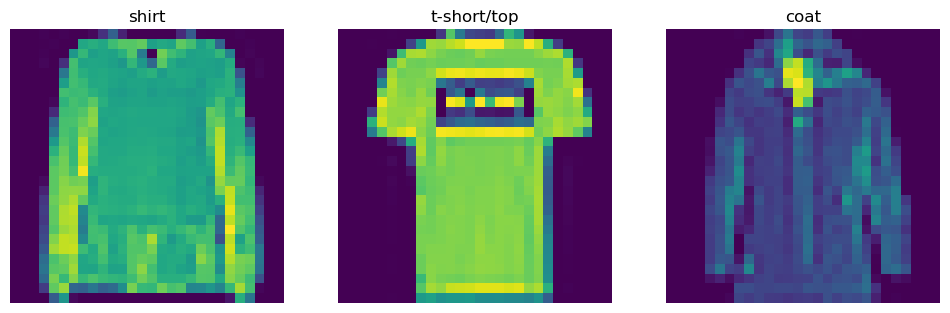

In [29]:
#Analysis: why are three of the classifers mostly strugging with short vs T-short/top?!!
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#for shirt
shirt_index = np.where(classes == 6)[0][0]
shirt_img = images[shirt_index]
axes[0].imshow(shirt_img)
axes[0].set_title("shirt")
axes[0].axis('off')

# for t-shirt/top
t_shirt_index = np.where(classes == 0)[0][0]
t_shirt_img = images[t_shirt_index]
axes[1].imshow(t_shirt_img)
axes[1].set_title("t-short/top")
axes[1].axis('off')

# for coat
coat_index = np.where(classes == 4)[0][0]
coat_img = images[coat_index]
axes[2].imshow(coat_img)
axes[2].set_title("coat")
axes[2].axis('off')

plt.show()

All correct: 7000 validation images
Only LR correct: 184 validation images
Only decision tree correct: 156 validation images
Only RF correct: 95 validation images
Only SVM correct: 65 validation images
All wrong: 646 validation images


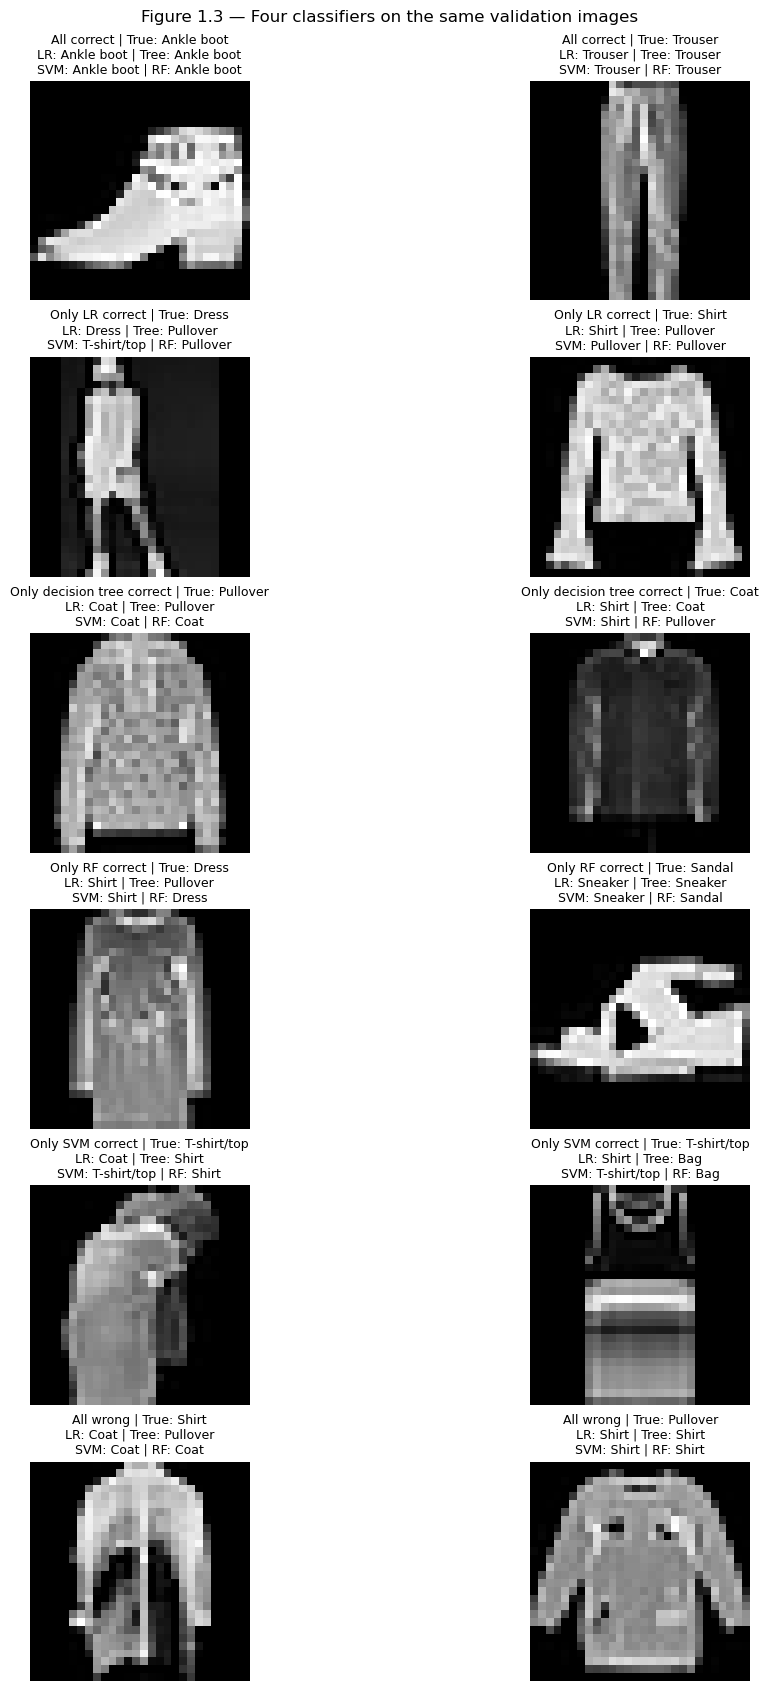

In [30]:
#comparing all four classifers on same images
#checking where all four were right, and were each of them were right
logreg_correct = val_predict_logreg == y_val
dectree_correct = val_predict_dectree == y_val
rf_correct = val_predict_rf == y_val
svm_correct = val_predict_svm == y_val

groups = [
    ("All correct", logreg_correct & dectree_correct & rf_correct & svm_correct),
    ("Only LR correct", logreg_correct & ~dectree_correct & ~rf_correct & ~svm_correct),
    ("Only decision tree correct", ~logreg_correct & dectree_correct & ~rf_correct & ~svm_correct),
    ("Only RF correct", ~logreg_correct & ~dectree_correct & rf_correct & ~svm_correct),
    ("Only SVM correct", ~logreg_correct & ~dectree_correct & ~rf_correct & svm_correct),
    ("All wrong", ~logreg_correct & ~dectree_correct & ~rf_correct & ~svm_correct),
]

rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(groups), 2, figsize=(10, 2.8 * len(groups)), layout="constrained")

for row, (outcome, mask) in enumerate(groups):
    positions = np.flatnonzero(mask)
    chosen = rng.choice(positions, size=min(2, len(positions)), replace=False)
    print(f"{outcome}: {len(positions)} validation images")

    for ax in axes[row]:
        ax.axis("off")

    if len(positions) == 0:
        axes[row, 0].set_title(f"{outcome} | 0 examples")

    for ax, pos in zip(axes[row], chosen):
        #ax.imshow(images[val_index[pos]], vmin=0, vmax=255)
        # (note: TDS said gray scale is better for comparison)
        ax.imshow(images[val_index[pos]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{outcome} | True: {class_names[y_val[pos]]}\n"
            f"LR: {class_names[val_predict_logreg[pos]]} | Tree: {class_names[val_predict_dectree[pos]]}\n"
            f"SVM: {class_names[val_predict_svm[pos]]} | RF: {class_names[val_predict_rf[pos]]}",
            fontsize=9,)

fig.suptitle("Figure 1.3 — Four classifiers on the same validation images")
fig.savefig("figures/part1_3_error_examples_4_classifiers.png", dpi=150, bbox_inches="tight")
plt.show()

<b> ** 1.3 - Error Analysis - final analysis ** </b>
* Shirt was hardest: recall was 62.6% for SVM, 59.6% for logistic regression, 56.7% for random forest and 45.1% for the decision tree.
* Of 1000 shirts, the first three models predicted 156, 144 and 166 as T-shirt/top; the tree predicted 184 as Coat.
* Figure 1.3 shows visual similarities between these classes and data quality issues where all models perform poorly.
* Trouser and Ankle boot were easier, with logistic-regression recall of 96.1% and 95.2%.
* Random forest’s 100% training accuracy needs comparison with validation performance for potential overfiting.

SVM correctly recognised 32 of these 144 shirts that LR missed.


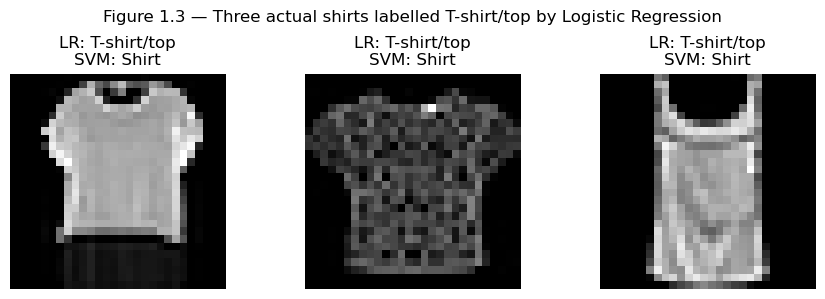

In [31]:
#visualizing to see what features of images SVM predicts correctly to double confirm
shirt_id = class_names.index("Shirt")
top_id = class_names.index("T-shirt/top")

# Positions in the validation set where LR called a true shirt a T-shirt/top.
positions = np.flatnonzero((y_val == shirt_id) & (val_predict_logreg == top_id))

svm_correct = np.sum(val_predict_svm[positions] == shirt_id)
print(f"SVM correctly recognised {svm_correct} of these {len(positions)} shirts that LR missed.")

svm_positions = np.flatnonzero((y_val == shirt_id) & (val_predict_logreg == top_id) & (val_predict_svm == shirt_id))
chosen = np.random.default_rng(42).choice(svm_positions, size=3, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, pos in zip(axes, chosen):
    ax.imshow(images[val_index[pos]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"LR: T-shirt/top\nSVM: {class_names[val_predict_svm[pos]]}")
    ax.axis("off")

fig.suptitle("Figure 1.3 — Three actual shirts labelled T-shirt/top by Logistic Regression")
fig.tight_layout()
fig.savefig("figures/part1_3_shirt_errors_svm.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
#coming back to 1.1 & 1.2 to justify chosing my models
#Finally chosing Logistic Regression and SVM based on above analysis
from sklearn.metrics import precision_recall_fscore_support
shirt_id = class_names.index("Shirt")
rows = []

for name, pred in [("Logistic Regression", val_predict_logreg), ("SVM", val_predict_svm)]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val == shirt_id, pred == shirt_id, average="binary", zero_division=0
    )
    false_positives = ((pred == shirt_id) & (y_val != shirt_id)).sum()
    rows.append([name, precision, recall, f1, false_positives])

print(pd.DataFrame(
    rows, columns=["Model", "Shirt precision", "Shirt recall", "Shirt F1", "False positives"]
).round(3).to_string(index=False))

              Model  Shirt precision  Shirt recall  Shirt F1  False positives
Logistic Regression            0.616         0.596     0.606              372
                SVM            0.705         0.626     0.663              262


***** <b>Task 1.1 - Models - My final justification revisited </b> *******.  
I finally selected logistic regression and SVM because:
* Both had higher Shirt recall: SVM achieved 62.6% and logistic regression 59.6% (see Task 1.3 on error analysis).
* They are also actually useful to learn from and compare two related characteritics: logistic regression still learns linear decision boundaries but the RBF SVM can also learn curved boundaries
* Both can be experimented for tuning later in this coursework: logistic regression can be tuned for regularisation (C value), similarly SVM can be tuned for gamma to evaluate performance.

<b> **  1.4 - My Plan ** </b>
* For logistic regression I want to vary the regularization strength across C values to assess the impact on performance and check for overfiting
* For SVM I am going to vary the gamma from 0.25, 1.0, 4.0 similarly to study the outcome 

 gamma_factor  gamma  train_accuracy  val_accuracy
         0.25 0.0026          0.8451        0.8389
         1.00 0.0102          0.8989        0.8674
         4.00 0.0410          0.9628        0.8737


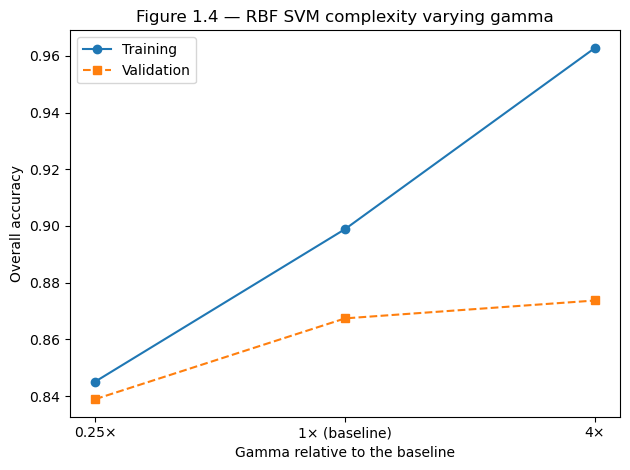

In [33]:
#to-do: should I do logistic regression fist? gamma analysis in SVM is simple and direct
from sklearn.base import clone

gamma_base = 1.0 / (X_fit.shape[1] * X_fit.var(dtype="float64"))
rows = []
for factor in [0.25, 1.0, 4.0]:
    gamma_value = factor * gamma_base
    fitted_svm = clone(svm).set_params(gamma=gamma_value)
    fitted_svm.fit(X_fit, y_fit)
    rows.append({
        "gamma_factor": factor,
        "gamma": gamma_value,
        "train_accuracy": fitted_svm.score(X_fit, y_fit),
        "val_accuracy": fitted_svm.score(X_val, y_val),})

gamma_results = pd.DataFrame(rows)
gamma_results.to_csv("results/part1_4_svm_gamma_study.csv", index=False)
print(gamma_results.round(4).to_string(index=False))

ax = gamma_results.plot(x="gamma_factor", y="train_accuracy", marker="o", label="Training")
gamma_results.plot(
    x="gamma_factor", y="val_accuracy", marker="s",
    linestyle="--", label="Validation", ax=ax)
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 1, 4], labels=["0.25×", "1× (baseline)", "4×"])
ax.set_xlabel("Gamma relative to the baseline")
ax.set_ylabel("Overall accuracy")
ax.set_title("Figure 1.4 — RBF SVM complexity varying gamma")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_svm_gamma_study.png", dpi=150)
plt.show()

In [34]:
#storing the best SVM configuration from the experiments above for later use
svm_selected = fitted_svm

In [35]:
baseline = gamma_results.loc[gamma_results["gamma_factor"] == 1.0].iloc[0]
best = gamma_results.loc[gamma_results["val_accuracy"].idxmax()]

val_gain_pp = 100 * (best["val_accuracy"] - baseline["val_accuracy"])
result = (f"Best of {len(gamma_results)} gamma settings by validation accuracy: "
    f"{best['gamma_factor']:g}× baseline (gamma={best['gamma']:.4f}, C=1.0). "
    f"Training accuracy {best['train_accuracy']:.2%}; "
    f"validation accuracy {best['val_accuracy']:.2%} "
    f"({val_gain_pp:+.2f} percentage points vs baseline).")
print(result)

exp_part1_svm_gamma = {
    "id": "P1-4_SVM_GAMMA-01",
    "question": "Does the change in gamma to the more local decision boundary improve validation accuracy, or does the benefit appear mainly on the training set?",
    "hypothesis": "For higher gamma, highest overall accuracy training set and highest overall accuracy  validation set",
    "changed_variable": "gamma = 0.25, 1.0 (scale), 4.0",
    "fixed_conditions": "C=1.0",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "kernel='rbf', C=1.0, gamma=varied, random_state=42",
    "metric": "overall training accuracy, overall validation accuracy",
    "result": {result},
    "output_path": ("results/part1_4_svm_gamma_study.csv; figures/part1_4_svm_gamma_study.png "),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_svm_gamma])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

Best of 3 gamma settings by validation accuracy: 4× baseline (gamma=0.0410, C=1.0). Training accuracy 96.28%; validation accuracy 87.37% (+0.63 percentage points vs baseline).


<b> ** 1.4 - My Analysis for SVM ** </b>
* Going from 0.25× to 1× improved validation accuracy by 2.85%. Going from 1× to 4× added only 0.63 percentage on validation, but training accuracy went up by 6.39%.
* So keeping C=1.0 fixed, making the SVM boundary local helped on validation images.
* The 4× gamma setting performed best on validation at 87.37%.
* This is a 0.63% more than baseline. So compared with the baseline, it correctly classified 63 more of the 10000 validation images
* But the larger gain was on the training set (96.28%)

/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


    C  train_accuracy  val_accuracy   gap
 0.01          0.8416        0.8374  0.42
 0.10          0.8865        0.8506  3.59
 1.00          0.9246        0.8408  8.38
10.00          0.9503        0.8162 13.41


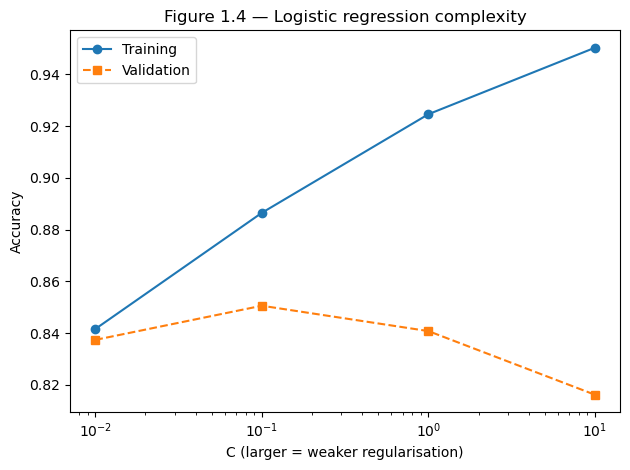

In [36]:
#now analysing logistic regression for varying regularisation strength/Cvalue
logreg_rows = []
for c_value in [0.01, 0.1, 1.0, 10.0]:
    if c_value == 1.0:
        fitted_logreg = logreg  # reusing the already fitted model earlier (todo: do the same for SVM above later)
    else:
        fitted_logreg = clone(logreg).set_params(C=c_value)
        fitted_logreg.fit(X_fit, y_fit)
    training_accuracy = fitted_logreg.score(X_fit, y_fit)
    validation_accuracy = fitted_logreg.score(X_val, y_val)
    logreg_rows.append({
        "C": c_value,
        "train_accuracy": training_accuracy,
        "val_accuracy": validation_accuracy,
        "gap": 100 * (training_accuracy - validation_accuracy),})

cvalue_results = pd.DataFrame(logreg_rows)
cvalue_results.to_csv("results/part1_4_logreg_cvalue_study.csv", index=False)
print(cvalue_results.round(4).to_string(index=False))

ax = cvalue_results.plot(x="C", y="train_accuracy", marker="o", label="Training", logx=True)
cvalue_results.plot(x="C", y="val_accuracy", marker="s", linestyle="--", label="Validation", ax=ax)
ax.set(xlabel="C (larger = weaker regularisation)", ylabel="Accuracy",
       title="Figure 1.4 — Logistic regression complexity")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_logreg_cvalye_study.png", dpi=150)
plt.show()


In [37]:
#this is interesting- one of the fits reached 500 iterations set as max before stopping
#there is some prediction but I need to rerun with higher limit to see if the outcome changes.
#so recording this experiment and running with allowing extended iteration
exp_part1_logreg_cvalue = {
    "id": "P1-4_LOGREG_CVALUE-01",
    "question": "Does weaker regularisation overfit the training data at a cost to generalisation?",
    "hypothesis": "Larger C improves training accuracy while validation accuracy falls",
    "changed_variable": "C = 0.01, 0.1, 1.0, 10.0",
    "fixed_conditions": "solver=lbfgs, max_iter=500",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "solver=lbfgs, max_iter=500",
    "metric": "training accuracy, validation accuracy",
    "result": "C=0.1 has the highest validation accuracy of 85.06% but one of the fit reached max iteration",
    "output_path": ("results/part1_4_logreg_cvalue_study.csv; figures/part1_4_logreg_cvalye_study.png"),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg_cvalue])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

    C  iterations  converged  train_accuracy  val_accuracy   gap
 0.01         177       True          0.8416        0.8374  0.42
 0.10         242       True          0.8865        0.8506  3.59
 1.00         405       True          0.9246        0.8408  8.38
10.00         812       True          0.9556        0.8160 13.96


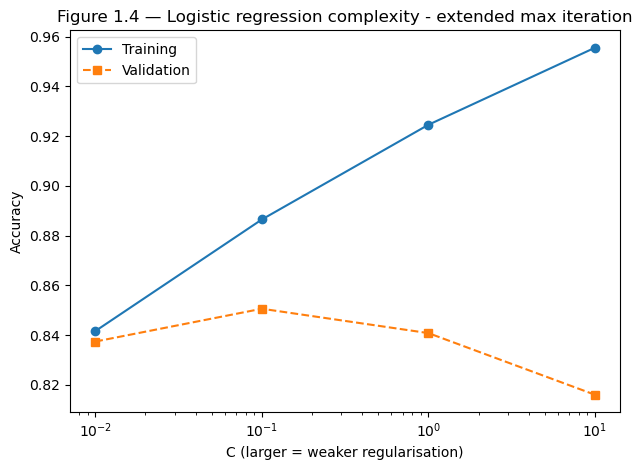

In [38]:
#now running with 2000 max interation and preparing to capture the warning
import warnings
from sklearn.exceptions import ConvergenceWarning
logreg_rows = []
logreg_models = {}

for c_value in [0.01, 0.1, 1.0, 10.0]:
    fitted_logreg = clone(logreg).set_params(C=c_value, max_iter=2000)

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        fitted_logreg.fit(X_fit, y_fit)

    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    train_accuracy = fitted_logreg.score(X_fit, y_fit)
    val_accuracy = fitted_logreg.score(X_val, y_val)
    logreg_models[c_value] = fitted_logreg
    logreg_rows.append({
        "C": c_value,
        "iterations": fitted_logreg.n_iter_.max(),
        "converged": converged,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "gap": 100 * (train_accuracy - val_accuracy),})

cvalue_results = pd.DataFrame(logreg_rows)
cvalue_results.to_csv("results/part1_4_logreg_cvalue_iter2000_study.csv", index=False)
print(cvalue_results.round(4).to_string(index=False))

ax = cvalue_results.plot(x="C", y="train_accuracy", marker="o", label="Training", logx=True)
cvalue_results.plot(x="C", y="val_accuracy", marker="s", linestyle="--", label="Validation", ax=ax)
ax.set(xlabel="C (larger = weaker regularisation)", ylabel="Accuracy",
       title="Figure 1.4 — Logistic regression complexity - extended max iteration")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_logreg_cvalue_iter2000_study.png", dpi=150)
plt.show()


<b>** 1.4 - My interpretation on Logistic Regression ** </b>
* 0.1 has the highest validation accuracy of 85.06%
* But C=10 reached 500 max iterations before the stopping condition is met. 
* All four converged on the second run and still C=0.1 achieved the highest validation accuracy of the four settings: 85.06%.
* The C=10 fit needed 812 iterations and hence caused the warning last time.
* Increasing C from 0.01 to 0.1 improved validation accuracy from 83.74% to 85.06%. Increasing it further to 10 raised training accuracy from 88.65% to 95.56%, but validation accuracy fell to 81.60%.
* This is evidence of overfiting at the higher setting: the model fitted the training images better and made more errors on new images

In [39]:
#storing the best logistic regressions setting for future use and analyis in later tasks
best_logreg_row = cvalue_results.loc[cvalue_results["val_accuracy"].idxmax()]
logreg_selected = logreg_models[best_logreg_row["C"]]

In [40]:
#recording the 2nd successful full run in the experiment register
exp_part1_logreg_cvalue_2 = {
    "id": "P1-4_LOGREG_CVALUE-02",
    "question": "Does increasing the max iteration converge all the C value fits?",
    "hypothesis": "All C fits coverage to identify the best C value",
    "changed_variable": "C = 0.01, 0.1, 1.0, 10.0 and max_iter=2000",
    "fixed_conditions": "solver=lbfgs",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "solver=lbfgs",
    "metric": "training accuracy, validation accuracy",
    "result": "All four fits converged. But C=0.1 still has the highest validation accuracy of 85.06%",
    "output_path": ("results/part1_4_logreg_cvalue_iter2000_study.csv; figures/part1_4_logreg_cvalue_iter2000_study.png.png"),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg_cvalue_2])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


<b> ** 1.5 - My approach ** </b>
* My binary decision problem --> When a user searches for "Footwear" in the catalogue, should a given item appear under the catalogue’s Footwear filter?
* There are 3000 footwear items and 7000 other items in the validation set of 10000 items
* If the catalogue allows atmost 1% of non-footwear items into the results, then that allows 70 false positives and maximum number of Footwear recovered.

In [41]:
#to-do:
from sklearn.metrics import roc_curve

footwear_ids = [class_names.index(c) for c in ["Sandal", "Sneaker", "Ankle boot"]]
is_footwear = np.isin(y_val, footwear_ids)
logreg_cols = np.isin(logreg_selected.classes_, footwear_ids)
svm_cols = np.isin(svm_selected.classes_, footwear_ids)
footwear_scores = {
    "Logistic regression": logreg_selected.predict_proba(X_val)[:, logreg_cols].sum(axis=1),
    "RBF SVM": svm_selected.decision_function(X_val)[:, svm_cols].max(axis=1),}

n_positive = int(is_footwear.sum())
n_negative = int((~is_footwear).sum())
rows = []
for model_name, scores in footwear_scores.items():
    fpr, recall, thresholds = roc_curve(is_footwear, scores, drop_intermediate=False)
    curve = pd.DataFrame({"threshold": thresholds,"FP": np.rint(fpr * n_negative).astype(int),
        "FN": n_positive - np.rint(recall * n_positive).astype(int),
        "footwear_recall": recall,})
    for budget in [35, 70, 140]:
        eligible = curve.loc[curve["FP"] <= budget]
        best = eligible.sort_values(["FN", "FP"]).iloc[0]
        rows.append({"model": model_name,"FP_budget": budget,"threshold": best["threshold"],
            "FP": int(best["FP"]),"FN": int(best["FN"]),
            "footwear_recall": best["footwear_recall"],})

footwear_results = pd.DataFrame(rows)
footwear_results.to_csv("results/part1_5_footwear_thresholds.csv", index=False)
print(footwear_results.round(4).to_string(index=False))

              model  FP_budget  threshold  FP  FN  footwear_recall
Logistic regression         35     0.3468  35   7           0.9977
Logistic regression         70     0.1799  70   2           0.9993
Logistic regression        140     0.1527  78   1           0.9997
            RBF SVM         35     8.2951  19   6           0.9980
            RBF SVM         70     8.2691  63   3           0.9990
            RBF SVM        140     8.2484 111   1           0.9997


<b> ** 1.5 - My final interpretation ** </b>
* Lowering the threshold reduced missed footwear (FN) but increased non-footwear items incorrectly included (FP).
* For logistic regression, lowering the threshold from 0.3468 to 0.1527 reduced FN from 7 to 1, but  FP increased from 35 to 78.
* For SVM, lowering the threshold from 8.2951 to 8.2484 reduced FN from 6 to 1, while FP increased from 19 to 111.
* When allowing 70 FPs, logistic regression missed one lesser footwear item than SVM but included seven more non-footwear items.
* At  140 FP limit, both missed one footwear item, but logistic regression included 33 lesser non-footwear items

<b> ** Part 2 - Neural networks: architecture and learning ** </b>

 <b>** 2.1 - My starting Settings ** </b>
* Architecture - 784 (input) -> 64 nodes (one hidden layer) -> 10 (output). One hidden layer for easy calcuation and baseline.
* Activation - ReLU after the hidden layer to learn nonlinear relationships between pixels better
* Loss - Cross-entropy on the ten output scores.
* Optimiser - Mini-batch SGD, learning rate 0.05, batch size 128.
* Training budget - 25 epochs.
* Initialisation - Fresh Xavier-uniform weights, zero biases,  seed 42 (purely based on internet research)

In [42]:
#defining the model and training procedure in this cell here
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

results_dir = Path("results/part2")
results_dir.mkdir(parents=True, exist_ok=True)

train_data = TensorDataset(torch.as_tensor(X_fit, dtype=torch.float32),
    torch.as_tensor(y_fit, dtype=torch.long),)
val_data = TensorDataset(torch.as_tensor(X_val, dtype=torch.float32),
    torch.as_tensor(y_val, dtype=torch.long),)
#my first ever module so keeping it simple
class FashionMLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(784, width)
        self.output = nn.Linear(width, 10)
        for layer in (self.hidden, self.output):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, pixels):
        features = torch.relu(self.hidden(pixels))
        return self.output(features)

def train_mlp(run_id, width=64, lr=0.05, seed=42, epochs=25):
    torch.manual_seed(seed)
    model = FashionMLP(width).to(device)

    # I must apparently reset this generator for each run so the mini-batches match across runs.
    order = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_data, batch_size=128, shuffle=True,generator=order)
    val_loader = DataLoader(val_data, batch_size=128, shuffle=False)
    loss_fn = nn.CrossEntropyLoss()
    optimiser = torch.optim.SGD(model.parameters(), lr=lr,momentum=0.0, weight_decay=0.0)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    checkpoint = results_dir / f"{run_id}.pt"
    best_val_loss = float("inf")
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss_sum = train_correct = 0
        for pixels, labels_batch in train_loader:
            pixels, labels_batch = pixels.to(device), labels_batch.to(device)
            optimiser.zero_grad()                # Clearing the previous batch's gradients
            logits = model(pixels)               # Computing ten scores per image here
            loss = loss_fn(logits, labels_batch)
            loss.backward()                      # Computing gradients by backpropagation
            optimiser.step()                     # SGD updates each weight
            train_loss_sum += loss.item() * len(labels_batch)
            train_correct += (logits.argmax(1) == labels_batch).sum().item()

        model.eval()
        val_loss_sum = val_correct = 0
        with torch.no_grad():
            for pixels, labels_batch in val_loader:
                pixels, labels_batch = pixels.to(device), labels_batch.to(device)
                logits = model(pixels)
                loss = loss_fn(logits, labels_batch)
                val_loss_sum += loss.item() * len(labels_batch)
                val_correct += (logits.argmax(1) == labels_batch).sum().item()
        val_loss = val_loss_sum / len(val_data)
        history.append({
            "run": run_id, "epoch": epoch, "width": width, "lr": lr,
            "seed": seed, "parameters": n_params,
            "train_loss": train_loss_sum / len(train_data), "val_loss": val_loss,
            "train_acc": train_correct / len(train_data),"val_acc": val_correct / len(val_data),})
        #this is my checkpoint, will repeat this check everywhere in future
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({
                "width": width, "epoch": epoch, "lr": lr, "seed": seed,
                "model_state": model.state_dict(),}, checkpoint)

    history = pd.DataFrame(history)
    history.to_csv(results_dir / f"{run_id}_history.csv", index=False)
    return history

Training device: cuda


[HAMI-core Msg(6540:139641595927872:libvgpu.c:855)]: Initialized


In [43]:
#runing the baseline architecture with one hidden layer of 64 nodes
from time import perf_counter

start = perf_counter()
baseline = train_mlp("P2-baseline64")
print(f"Baseline training time: {perf_counter() - start:.1f} seconds")

best = baseline.loc[baseline["val_loss"].idxmin()]
exp_part2_1_baseline = {
    "id": "P2_1-BASELINE-01",
     "question": "How well does a single-hidden-layer MLP perform in a fixed training recipe?",
    "hypothesis": "Training and validation performance will improve as the MLP learns.",
    "changed_variable": "None; baseline configuration",
    "fixed_conditions": (
        "784 features; Xavier-uniform weights; zero biases; "
        "cross-entropy; first minimum-validation-loss checkpoint"),
    "split": "10,000 fitting images; 10,000 validation images",
    "seed": "Model initialisation=42; training shuffle generator=42",
    "configuration": (
        "Architecture=784-64-10; hidden activation=ReLU; parameters=50890; "
        "optimiser=SGD; learning_rate=0.05; batch_size=128; epochs=25; "
        "momentum=0; weight_decay=0"),
    "metric": "Per-epoch cross-entropy and accuracy on training and validation",
    "result": (
        f"Best epoch={int(best['epoch'])}; "
        f"parameters={int(best['parameters'])}; "
        f"training_loss={best['train_loss']:.6f}; "
        f"validation_loss={best['val_loss']:.6f}; "
        f"training_accuracy={best['train_acc']:.2%}; "
        f"validation_accuracy={best['val_acc']:.2%}"),
    "output_path": (
        "results/part2/P2-baseline64_history.csv; "
        "results/part2/P2-baseline64.pt"),}

register_path = Path("results/experiment_register.csv")
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part2_1_baseline])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_part2_1_baseline["result"])


Baseline training time: 12.9 seconds
Best epoch=22; parameters=50890; training_loss=0.408506; validation_loss=0.436975; training_accuracy=85.83%; validation_accuracy=84.50%


<b> **2.2 - Capacity - My approach ** <b>
* Comparing three MLPs with one hidden layer: 32, 64 (baseline) and 256 units.

 width  parameters  epoch  train_loss  val_loss  train_acc  val_acc
    32       25450     22      0.4277    0.4506     0.8508   0.8404
    64       50890     22      0.4085    0.4370     0.8583   0.8450
   256      203530     22      0.3937    0.4255     0.8654   0.8497


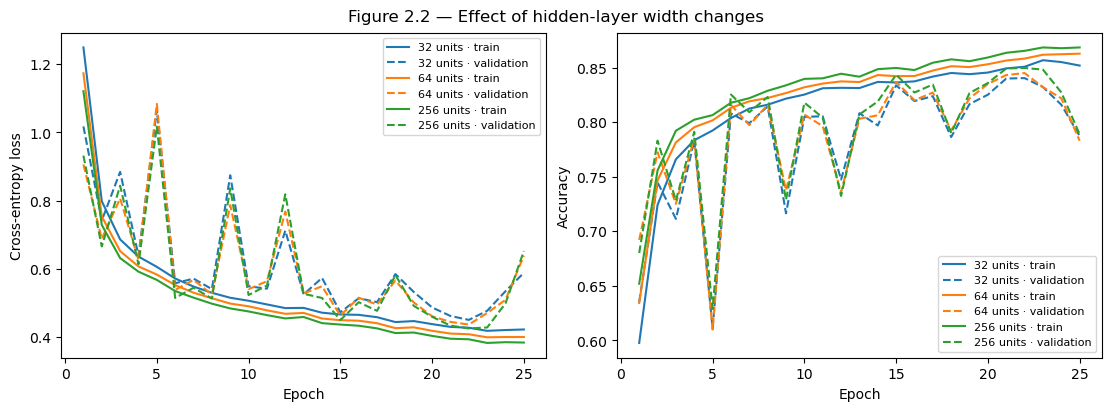

width=32, parameters=25450, selected_epoch=22, training_loss=0.427650, validation_loss=0.450575, training_accuracy=85.08%, validation_accuracy=84.04% | width=64, parameters=50890, selected_epoch=22, training_loss=0.408506, validation_loss=0.436975, training_accuracy=85.83%, validation_accuracy=84.50% | width=256, parameters=203530, selected_epoch=22, training_loss=0.393743, validation_loss=0.425524, training_accuracy=86.54%, validation_accuracy=84.97%


In [44]:
# 2.2 — Capacity experiment: varying only the hidden-layer width.
capacity_runs = {
    32: train_mlp("P2-width32", width=32),
    64: baseline,
    256: train_mlp("P2-width256", width=256),} #note for later, tried 512 before

# Comparing each width at its lowest validation loss checkpoint.
capacity_summary = pd.DataFrame([
    history.loc[history["val_loss"].idxmin()]
    for history in capacity_runs.values()
])[["width", "parameters", "epoch", "train_loss", "val_loss", "train_acc", "val_acc"]]
capacity_summary.to_csv(results_dir / "2.2_capacity_summary.csv", index=False)
print(capacity_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for width, history in capacity_runs.items():
    for ax, metric in zip(axes, ["loss", "acc"]):
        line, = ax.plot(history["epoch"], history[f"train_{metric}"],
                        label=f"{width} units · train")
        ax.plot(history["epoch"], history[f"val_{metric}"], "--",
                color=line.get_color(), label=f"{width} units · validation")

for ax, ylabel in zip(axes, ["Cross-entropy loss", "Accuracy"]):
    ax.set(xlabel="Epoch", ylabel=ylabel)
    ax.legend(fontsize=8)
fig.suptitle("Figure 2.2 — Effect of hidden-layer width changes")
fig.savefig(results_dir / "2.2_capacity_curves.png", dpi=150)
plt.show()

result_entries = []
for _, row in capacity_summary.sort_values("width").iterrows():
    result_entries.append(
        f"width={int(row['width'])}, "
        f"parameters={int(row['parameters'])}, "
        f"selected_epoch={int(row['epoch'])}, "
        f"training_loss={row['train_loss']:.6f}, "
        f"validation_loss={row['val_loss']:.6f}, "
        f"training_accuracy={row['train_acc']:.2%}, "
        f"validation_accuracy={row['val_acc']:.2%}")

exp_part2_2_capacity = {
    "id": "P2_2-CAPACITY-01",
    "question": "How does hidden-layer width affect training fit and validation?",
    "hypothesis": ("Wider networks may achieve lower training loss, while validation "
        "gains may be smaller because of overfitting or optimisation limits."),
    "changed_variable": "Hidden-layer width: 32, 64, 256",
    "fixed_conditions": ("One hidden layer; ReLU; Xavier-uniform weights; zero biases; "
        "same saved fitting/validation indices and training batch order"),
    "split": "10,000 fitting images; 10,000 validation images",
    "seed": "Model initialisation=42; training shuffle generator=42",
    "configuration": ("Architectures=784-32-10, 784-64-10, 784-256-10; "
        "parameters=25450, 50890, 203530; "
        "loss=cross-entropy; optimiser=SGD; learning_rate=0.05; "
        "batch_size=128; epochs=25; momentum=0; weight_decay=0; "
        "checkpoint=first minimum validation loss for each run"),
    "metric": ("Per-epoch training/validation cross-entropy and accuracy; "
        "parameter counts; selected epoch"),
    "result": " ",
    "output_path": (
        "results/part2/2.2_capacity_summary.csv; "
        "results/part2/2.2_capacity_curves.png"),}
exp_part2_2_capacity["result"] = " | ".join(result_entries)

register_path = Path("results/experiment_register.csv")
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part2_2_capacity])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_part2_2_capacity["result"])


<b> ** 2.2 - Capacity - My final interpretation ** </b>
* Figure 2.2 shows better training fit as width increases. Training accuracy went up from 85.08% with 32 units to 85.83% with 64 and down a bit at 86.54% with 256.
* Validation accuracy also improved: 84.04%, 84.50% and 84.97%. The 256-unit model correctly classified 93 more validation images than the 32-unit model.
* Compared with the baseline, 256 units used four times more parameters for 47 additional correct validation predictions. Its not a good justification of cost.
* Validation loss fell from 0.4506 to 0.4370 to 0.4255. So far all three models selected epoch 22 using minimum validation loss.
* But Figure 2.2 shows very large validation fluctuations. This shows performance within 25 epochs but it is not yet a fully optimised models.

<b>** 2.3 - My plan ** </b>
* Comparing learning rates of 0.005, 0.05 and 0.2 to test how step size impacts learning speed and validation performance.
* Everything else is same

              run  width    lr  parameters  selected_epoch  train_loss  val_loss  train_acc  val_acc  training_seconds
P2-lr0005-width64     64 0.005       50890              25    0.631183  0.627326     0.7969   0.7969         12.896516
    P2-baseline64     64 0.050       50890              22    0.408506  0.436975     0.8583   0.8450          6.900000
  P2-lr02-width64     64 0.200       50890              22    0.312237  0.381955     0.8878   0.8598         12.736603


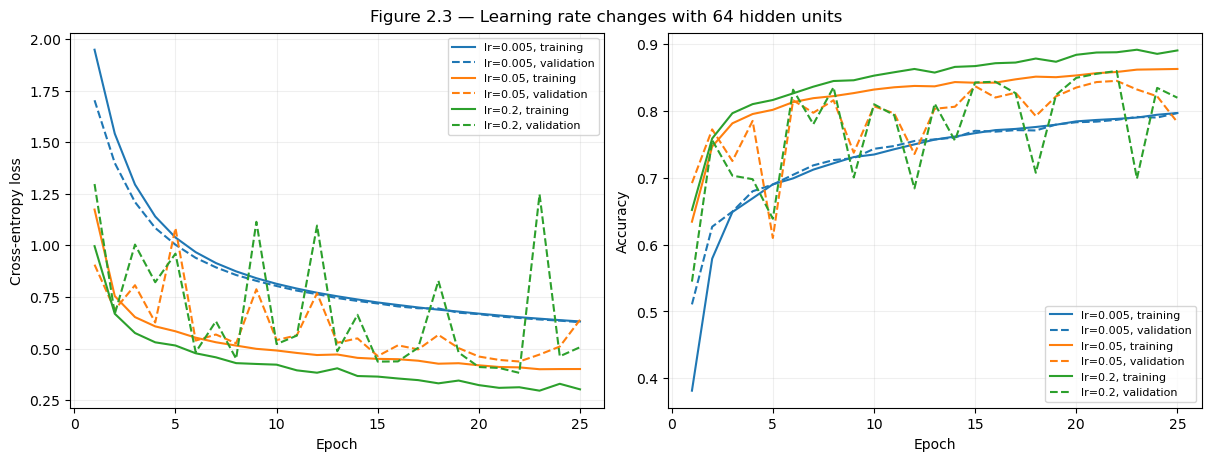

lr=0.005, selected_epoch=25, training_loss=0.631183, validation_loss=0.627326, training_accuracy=79.69%, validation_accuracy=79.69%, training_seconds=12.90 | lr=0.05, selected_epoch=22, training_loss=0.408506, validation_loss=0.436975, training_accuracy=85.83%, validation_accuracy=84.50%, training_seconds=6.90 | lr=0.2, selected_epoch=22, training_loss=0.312237, validation_loss=0.381955, training_accuracy=88.78%, validation_accuracy=85.98%, training_seconds=12.74


In [45]:
# 2.3 — Optimisation: varying only the learning rate.
from pathlib import Path
from time import perf_counter

results_dir = Path("results/part2")
results_dir.mkdir(parents=True, exist_ok=True)
optimisation_choices = {0.05: baseline}
training_times = {0.05: 6.9}  # this will be measured time from the completed baseline.

for learning_rate, run_id in [(0.005, "P2-lr0005-width64"),(0.2, "P2-lr02-width64"),]:
    start = perf_counter()
    optimisation_choices[learning_rate] = train_mlp(run_id,width=64,
        lr=learning_rate,seed=42,epochs=25,)
    training_times[learning_rate] = perf_counter() - start
# Select each run checkpoint using lowest validation loss.
summary_rows = []
for learning_rate in sorted(optimisation_choices):
    history = optimisation_choices[learning_rate]
    best = history.loc[history["val_loss"].idxmin()]
    summary_rows.append({"run": best["run"], "width": int(best["width"]),
        "lr": learning_rate, "parameters": int(best["parameters"]),
        "selected_epoch": int(best["epoch"]),"train_loss": best["train_loss"],
        "val_loss": best["val_loss"],"train_acc": best["train_acc"],
        "val_acc": best["val_acc"],"training_seconds": training_times[learning_rate],})

optimisation_summary = pd.DataFrame(summary_rows)
summary_path = results_dir / "2.3_optimisation_summary.csv"
history_path = results_dir / "2.3_optimisation_history.csv"
figure_path = results_dir / "2.3_optimisation_curves.png"

optimisation_summary.to_csv(summary_path, index=False)
pd.concat([optimisation_choices[lr] for lr in sorted(optimisation_choices)],
    ignore_index=True,).to_csv(history_path, index=False)
print(optimisation_summary.round(6).to_string(index=False))

# Learning curves: here the colour show learning rate;solid/dashed lines show training/validation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for learning_rate in sorted(optimisation_choices):
    history = optimisation_choices[learning_rate]
    for ax, metric in zip(axes, ["loss", "acc"]):
        line, = ax.plot(history["epoch"],history[f"train_{metric}"],
            label=f"lr={learning_rate:g}, training",)
        ax.plot(history["epoch"],history[f"val_{metric}"],linestyle="--",
            color=line.get_color(),label=f"lr={learning_rate:g}, validation",)

for ax, ylabel in zip(axes, ["Cross-entropy loss", "Accuracy"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.suptitle("Figure 2.3 — Learning rate changes with 64 hidden units")
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

result_entries = []
for _, row in optimisation_summary.iterrows():
    result_entries.append(
        f"lr={row['lr']:g}, "
        f"selected_epoch={int(row['selected_epoch'])}, "
        f"training_loss={row['train_loss']:.6f}, "
        f"validation_loss={row['val_loss']:.6f}, "
        f"training_accuracy={row['train_acc']:.2%}, "
        f"validation_accuracy={row['val_acc']:.2%}, "
        f"training_seconds={row['training_seconds']:.2f}")

exp_optimisation = {"id": "P2_3-OPTIMISATION-01",
    "question":"How does learning rate affect training dynamics and validation?",
    "hypothesis": (
        "The smaller learning rate may learn more slowly. "
        "The larger learning rate may improve progress but could cause "
        "oscillation or instability."),
    "changed_variable": "SGD learning rate: 0.005, 0.05, 0.2",
    "fixed_conditions": (
        "Architecture=784-64-10; parameters=50890; ReLU; "
        "Xavier-uniform weights; zero biases; "
        "same saved image indices; float32 pixels divided by 255; "
        "same initialisation seed and training batch order"),
    "split": "10,000 fitting images; 10,000 validation images",
    "seed": "Model initialisation=42; training shuffle generator=42",
    "configuration": (
        "Loss=cross-entropy; optimiser=SGD; batch_size=128; "
        "epochs=25; momentum=0; weight_decay=0; "
        "checkpoint=first minimum validation loss per run; "
        "lr=0.05 reuses P2-baseline64"),
    "metric": (
        "Per-epoch training/validation cross-entropy and accuracy; "
        "selected epoch; total training runtime"),
    "result": " | ".join(result_entries),
    "output_path": (
        f"{summary_path}; {history_path}; {figure_path}; "
        f"{results_dir / 'P2-baseline64.pt'}; "
        f"{results_dir / 'P2-lr0005-width64.pt'}; "
        f"{results_dir / 'P2-lr02-width64.pt'}"),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part2_2_capacity])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_optimisation["result"])

<b> ** 2.3 - Optimisation - My final interpretation ** </b>
* Figure 2.3 shows that 0.005 learned smoothly but slowly, going to 79.69% validation accuracy at epoch 25. It was still improving, so the fixed budget may limit this setting.
* The baseline rate of 0.05 reached 84.50%. The rate of 0.2 achieved the best selected accuracy, 85.98% which is 148 more correct validation predictions than the baseline.
* But also, higher rates created larger validation fluctuations. At 0.2, validation loss spiked up  sharply near epoch 23. But the spike is not overfiting?!
* 0.2 achieved 85.98% at the selected epoch 22, compared with approximately 82% at epoch 25.
* For seed 42, 0.2 performed best within 25 epochs. But it may changes for other setting with longer training

<b> **** Part 3: Overfitting, regularisation and randomness  ****** <b>

<b>** 3.1 - My plan ** </b>
* Train three configuration versions of the same network: (1) Unregularised using Standard SGD reference benchmark (2) Weight decay and (3) Dropout as an alternative strategy
* Everything else is fixed.

In [46]:
import random

results_dir = Path("results/part3")
results_dir.mkdir(parents=True, exist_ok=True)
class RegularisedMLP(FashionMLP):
    def __init__(self, width=64, dropout=0.0):
        super().__init__(width)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, pixels):
        features = torch.relu(self.hidden(pixels))
        features = self.dropout(features)
        return self.output(features)

def evaluate_regularisation(model, loader, loss_fn):
    #Measure plain cross-entropy and accuracy with fixed weights
    model.eval()
    loss_sum, correct = 0.0, 0
    with torch.no_grad():
        for pixels, targets in loader:
            pixels = pixels.to(device)
            targets = targets.to(device)
            logits = model(pixels)
            loss_sum += loss_fn(logits, targets).item() * len(targets)
            correct += (logits.argmax(1) == targets).sum().item()
    return loss_sum / len(loader.dataset), correct / len(loader.dataset)

def train_regularisation(condition, seed, weight_decay=0.0,dropout=0.0,lr=0.01, width=256, epochs=500,):
    # seed below controls initialisation, dropout and any Python/NumPy randomness.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = RegularisedMLP(width=width, dropout=dropout).to(device)  
    n_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    run_id = f"P3-w{width}-e{epochs}-l{lr}-{condition}-seed{seed}"

    # like before, an independent generator keeps batch order matched across conditions
    train_loader = DataLoader(train_data,batch_size=128,shuffle=True,
        generator=torch.Generator().manual_seed(seed),num_workers=0,)
    train_eval_loader = DataLoader(train_data,batch_size=128,shuffle=False,
        generator=torch.Generator().manual_seed(0),num_workers=0,)
    val_eval_loader = DataLoader(val_data,batch_size=128,shuffle=False,
        generator=torch.Generator().manual_seed(0),num_workers=0,)

    loss_fn = nn.CrossEntropyLoss()
    optimiser = torch.optim.SGD(model.parameters(),lr=lr,momentum=0.0,
        weight_decay=weight_decay,)

    history = []
    best_val_loss = float("inf")
    start = perf_counter()
    # Training for the configured epoch and selecting a checkpoint by validation loss
    for epoch in range(1, epochs + 1):
        model.train()
        for pixels, targets in train_loader:
            pixels = pixels.to(device)
            targets = targets.to(device)
            optimiser.zero_grad()
            logits = model(pixels)
            loss = loss_fn(logits, targets)
            loss.backward()
            optimiser.step()

        train_loss, train_acc = evaluate_regularisation(model, train_eval_loader, loss_fn)
        val_loss, val_acc = evaluate_regularisation(model, val_eval_loader, loss_fn)

        history.append({"run": run_id,"condition": condition,"seed": seed,"width": width,
            "parameters": n_parameters,"epoch_budget": epochs,"epoch": epoch,
            "weight_decay": weight_decay, "dropout": dropout, "train_loss": train_loss,
            "val_loss": val_loss, "train_acc": train_acc,"val_acc": val_acc,
            "lr": lr, "batch_size": 128,"gap_pp": 100 * (train_acc - val_acc),})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({ "model_state": model.state_dict(),"width": width,"parameters": n_parameters,
                "epoch_budget": epochs,"epoch": epoch,"seed": seed,"lr": lr,"batch_size": 128,
                "weight_decay": weight_decay,"dropout": dropout, }, results_dir / f"{run_id}.pt")

    elapsed = perf_counter() - start
    history = pd.DataFrame(history)
    history.to_csv(results_dir / f"{run_id}_history.csv", index=False)
    best = history.loc[history["val_loss"].idxmin()].to_dict()
    best["training_seconds"] = elapsed
    print(f"{run_id}: selected epoch={best['epoch']}, "
        f"validation accuracy={best['val_acc']:.2%}")
    return history, best

<b>** 3.2 - My plan ** </b>
* Each configuration version (unregularised, weight delay and dropout) is trained with seeds 42, 43 and 44. Changing the seed changes the initial weights and training-image order.
* Evaluate if the regularisation is consistent

In [47]:
conditions = {
    "unregularised": {"weight_decay": 0.0, "dropout": 0.0},
    "weight_decay": {"weight_decay": 0.001, "dropout": 0.0},
    "dropout": {"weight_decay": 0.0, "dropout": 0.2},}

seeds = [42, 43, 44]
regularisation_histories = []
regularisation_results = []
for condition, settings in conditions.items():
    for seed in seeds:
        history, result = train_regularisation(
            condition=condition, seed=seed, **settings,lr=0.01,width=256,epochs=500,)
        # The existing fields in result describe the selected checkpoint.
        final = history.iloc[-1]
        result.update({"final_epoch": int(final["epoch"]), "final_train_loss": final["train_loss"],
            "final_val_loss": final["val_loss"],"final_train_acc": final["train_acc"],
            "final_val_acc": final["val_acc"],"final_gap_pp": final["gap_pp"],})
        regularisation_histories.append(history)
        regularisation_results.append(result)

regularisation_history = pd.concat(regularisation_histories, ignore_index=True)
regularisation_summary = pd.DataFrame(regularisation_results)
regularisation_history.to_csv(results_dir / "all_learning_curves.csv", index=False)
regularisation_summary.to_csv(results_dir / "seed_results.csv", index=False)
print("\nSelected-checkpoint results")
print(regularisation_summary[["condition", "seed", "epoch", "train_loss",
         "val_loss", "train_acc", "val_acc", "gap_pp"]].round(4).to_string(index=False))
print("\nFinal-epoch results")
print(regularisation_summary[["condition", "seed", "final_epoch",
         "final_train_loss", "final_val_loss",
         "final_train_acc", "final_val_acc", "final_gap_pp"]].round(4).to_string(index=False))

aggregate = regularisation_summary.groupby("condition").agg(
    number_of_seeds=("seed", "nunique"),
    val_accuracy_mean=("val_acc", "mean"),
    val_accuracy_sample_std=("val_acc", "std"),
    val_loss_mean=("val_loss", "mean"),
    val_loss_sample_std=("val_loss", "std"),
    gap_pp_mean=("gap_pp", "mean"),
    final_val_accuracy_mean=("final_val_acc", "mean"),
    final_val_accuracy_sample_std=("final_val_acc", "std"),
    final_val_loss_mean=("final_val_loss", "mean"),
    final_val_loss_sample_std=("final_val_loss", "std"),
    final_gap_pp_mean=("final_gap_pp", "mean"),)
aggregate.to_csv(results_dir / "mean_and_sample_std.csv")
print("\nMean and sample standard deviation across three seeds")
print(aggregate.round(6).to_string())

# Paired accuracy improvements at selected checkpoints.
selected_accuracy = regularisation_summary.pivot(
    index="seed", columns="condition", values="val_acc")
final_accuracy = regularisation_summary.pivot(
    index="seed", columns="condition", values="final_val_acc")
paired = pd.DataFrame(index=selected_accuracy.index)
for condition in ["weight_decay", "dropout"]:
    paired[f"{condition}_selected_gain_percentage"] =  100 * (
        selected_accuracy[condition] - selected_accuracy["unregularised"])
    paired[f"{condition}_final_gain_percentage"] = 100 * (
        final_accuracy[condition] - final_accuracy["unregularised"])
paired.to_csv(results_dir / "paired_accuracy_comparison.csv")
print("\nPaired accuracy improvements, in percentage points")
print(paired.round(2).to_string())

P3-w256-e500-l0.01-unregularised-seed42: selected epoch=347, validation accuracy=86.53%
P3-w256-e500-l0.01-unregularised-seed43: selected epoch=264, validation accuracy=86.57%
P3-w256-e500-l0.01-unregularised-seed44: selected epoch=364, validation accuracy=86.66%
P3-w256-e500-l0.01-weight_decay-seed42: selected epoch=485, validation accuracy=86.77%
P3-w256-e500-l0.01-weight_decay-seed43: selected epoch=494, validation accuracy=86.89%
P3-w256-e500-l0.01-weight_decay-seed44: selected epoch=481, validation accuracy=86.90%
P3-w256-e500-l0.01-dropout-seed42: selected epoch=451, validation accuracy=87.59%
P3-w256-e500-l0.01-dropout-seed43: selected epoch=482, validation accuracy=87.56%
P3-w256-e500-l0.01-dropout-seed44: selected epoch=497, validation accuracy=87.57%

Selected-checkpoint results
    condition  seed  epoch  train_loss  val_loss  train_acc  val_acc  gap_pp
unregularised    42    347      0.2276    0.3844     0.9273   0.8653    6.20
unregularised    43    264      0.2649    0.38

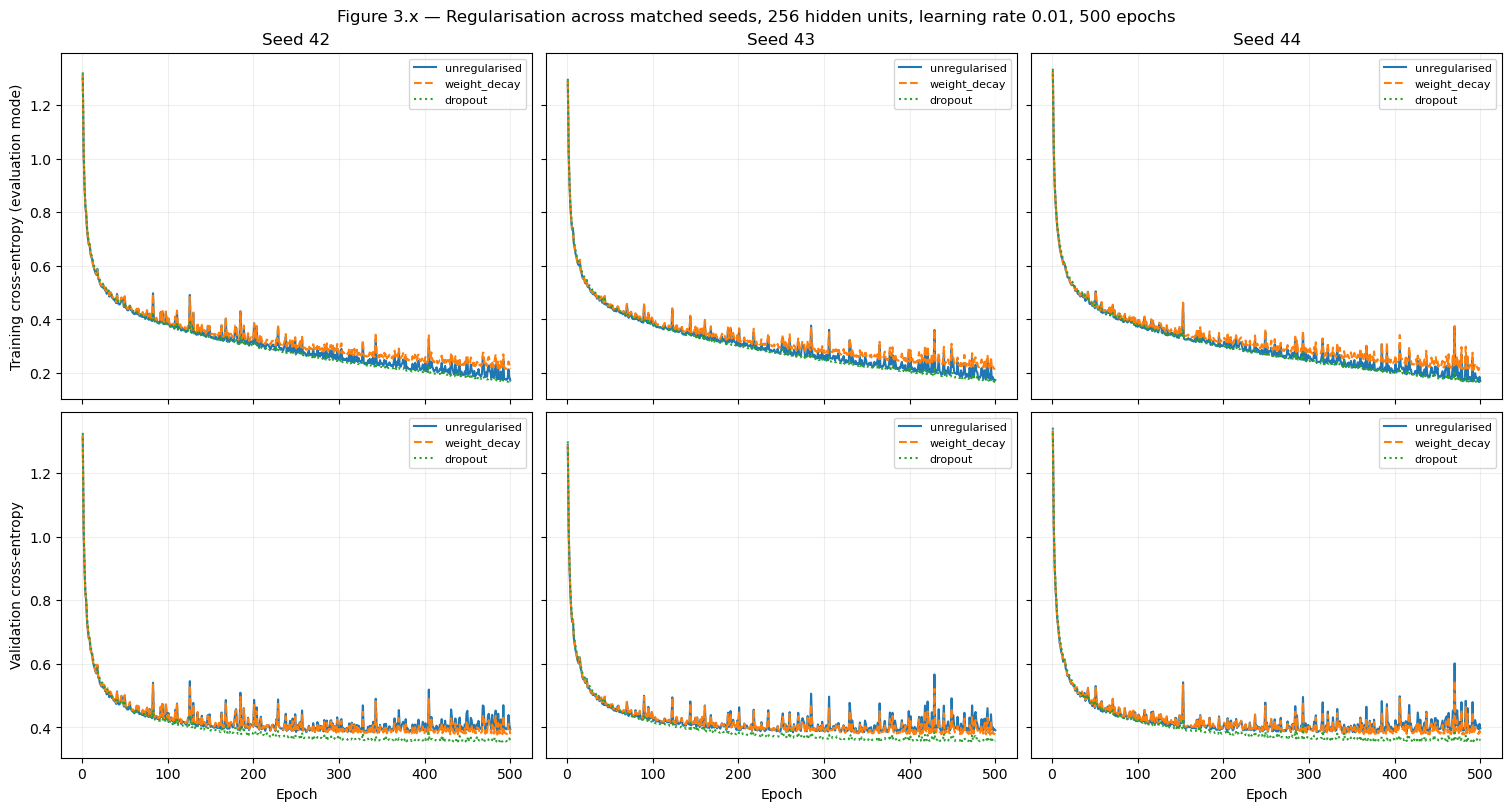

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey="row",layout="constrained")
styles = {
    "unregularised": ("tab:blue", "-"),
    "weight_decay": ("tab:orange", "--"),
    "dropout": ("tab:green", ":"),}

for column, seed in enumerate(seeds):
    for condition, (colour, linestyle) in styles.items():
        history = regularisation_history.loc[
            (regularisation_history["seed"] == seed)
            & (regularisation_history["condition"] == condition)].sort_values("epoch")
        for row, metric in enumerate(["train_loss", "val_loss"]):
            axes[row, column].plot(history["epoch"],history[metric],color=colour,
                linestyle=linestyle,label=condition,)
    axes[0, column].set_title(f"Seed {seed}")
    axes[1, column].set_xlabel("Epoch")
for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel("Training cross-entropy (evaluation mode)")
axes[1, 0].set_ylabel("Validation cross-entropy")
fig.suptitle("Figure 3.x — Regularisation across matched seeds, 256 hidden units, learning rate 0.01, 500 epochs")
fig.savefig(results_dir / "regularisation_curves.png", dpi=150)
plt.show()

<b>** 3.1 - My Interpreation ** </b>
* Figure 3.x and the checkpoint results show late overfitting: unregularised training loss fell while validation loss rose by epoch 500 in all seeds.
* Dropout gave the best validation accuracy: 87.57%, versus 86.59% unregularised and 86.85% with weight decay.
* Weight decay produced the smallest training to validation gap, but dropout achieved better validation performance.

<b> ** 3.2 - Randomness - My Interpretation ** </b>
* Dropout improved accuracy by 0.91 to 1.06% across seeds; weight decay gained 0.24 to 0.32%.
* Figure 3.x shows different fluctuations across seeds.
* Three seeds give limited evidence of variability and do not show much effect

In [49]:
from pathlib import Path
import pandas as pd

# build the result text from the measured results.
result_entries = []
for _, row in regularisation_summary.sort_values(["condition", "seed"]).iterrows():
    result_entries.append(f"{row['condition']}, seed={int(row['seed'])}, "
        f"selected_epoch={int(row['epoch'])}, "
        f"selected_train_loss={row['train_loss']:.6f}, "
        f"selected_val_loss={row['val_loss']:.6f}, "
        f"selected_train_accuracy={row['train_acc']:.2%}, "
        f"selected_val_accuracy={row['val_acc']:.2%}, "
        f"final_epoch={int(row['final_epoch'])}, "
        f"final_train_loss={row['final_train_loss']:.6f}, "
        f"final_val_loss={row['final_val_loss']:.6f}, "
        f"final_train_accuracy={row['final_train_acc']:.2%}, "
        f"final_val_accuracy={row['final_val_acc']:.2%}, "
        f"training_seconds={row['training_seconds']:.2f}")

exp_regularisation = {
    "id": "P3_REGULARISATION_01",
    "question": "How do weight decay and dropout affect generalisation during extended training?",
    "hypothesis": ("Continued training may improve training fit after validation "
        "improvements saturate. Regularisation may improve validation "
        "performance or reduce later deterioration, with effects varying across seeds."),
    "changed_variable": ("Regularisation: none; weight_decay=0.001; dropout=0.2. "
        "Each condition repeated with seeds 42,43,44."),
    "fixed_conditions": ("Architecture=784-256-10; parameters=203530; ReLU; "
        "Xavier-uniform weights; zero biases; "
        "saved fitting/validation indices; float32 pixels divided by 255 and flattened to 784 features; "
        "matched initial weights and mini-batch order within each seed"),
    "split": (f"Fitting images={len(train_data)}; "
        f"validation images={len(val_data)}"),
    "seed": ("42,43,44; Python, NumPy and PyTorch seeded; "
        "independent training-loader generator seeded per run; "
        "evaluation-loader generators seeded 0; num_workers=0; "
        "PyTorch seed also controls dropout masking"),
    "configuration": ("SGD; learning_rate=0.01; batch_size=128; epochs=500; "
        "momentum=0; loss=cross-entropy; "
        "weight decay applies to weights and biases; "
        "dropout follows hidden ReLU; "
        "checkpoint=first minimum validation cross-entropy; "
        f"device={device}"),
    "metric": ("End-of-epoch training/validation cross-entropy and accuracy "
        "in evaluation mode; cross-entropy excludes weight-decay penalty; "
        "selected-checkpoint and final-epoch results; "
        "mean and sample standard deviation (ddof=1) across three seeds; "
        "paired accuracy differences in percentage points"),
    "result": " | ".join(result_entries),
    "output_path": "; ".join(
        str(results_dir / filename)
        for filename in [
            "all_learning_curves.csv",
            "seed_results.csv",
            "mean_and_sample_std.csv",
            "paired_accuracy_comparison.csv",
            "regularisation_curves.png",]),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_regularisation])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

<b>** Part 4 : Clustering: structure without labels ** </b>

<b>** 4.1 - My plan **</b>
* K values - 2 to 20
* Random seeds - 42, 43, 44
* Initial search - k-means++, 10 restarts/seed
* Selection rule - highest mean validation silhouette
* Stability experiment - random versus k-means++, each with 1 versus 10 restarts
* Other fit settings - Lloyd algorithm, maximum 300 iterations, tolerance 1e-4
* Measuring approach
  * For selecting K -- silhouette measures how close an image is to its own cluster compared with neighbouring clusters.
  * For stability -- Adjusted Rand Index (ARI) compares two runs’ assignments on the same validation images. Here we compare cluster assignments against other cluster assignments, using no clothing labels

In [50]:
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
part4_dir = Path("results/part4_1")
part4_dir.mkdir(parents=True, exist_ok=True)

X_cluster_train = (images[cluster_train_index].astype(np.float32).reshape(-1, 784) / 255.0)
X_cluster_val = (images[cluster_val_index].astype(np.float32).reshape(-1, 784) / 255.0)
K_VALUES = [2, 4, 6, 8, 10, 12, 15, 20]
SEEDS = [42, 43, 44]

protocol = {
    "images": "784 raw pixels, float32, divided by 255",
    "training_images": 3000,
    "validation_images": 1000,
    "k_values": K_VALUES,
    "seeds": SEEDS,
    "selection_init": "k-means++",
    "selection_n_init": 10,
    "selection_rule": ( "Highest mean validation silhouette across three seeds; "),
    "stability_init": ["random", "k-means++"],
    "stability_n_init": [1, 10],
    "algorithm": "lloyd",
    "max_iter": 300,
    "tol": 1e-4,
    "distance": "Euclidean; squared for inertia",}
with open(part4_dir / "protocol.json", "w") as file:
    json.dump(protocol, file, indent=2)

#saving the exact indices used so I can use them in the next session
cluster_indices = {"train_index": cluster_train_index.tolist(),
    "val_index": cluster_val_index.tolist() }
with open(part4_dir / "used_indices.json", "w") as f:
    json.dump(cluster_indices, f)

In [51]:
import joblib

#creating a helperfunction so I can call these with different K values & seeds later
def fit_raw_kmeans(k, seed, init, n_init, phase):
    run_id = f"{phase}-k{k}-{init}-ninit{n_init}-seed{seed}"

    model = KMeans(n_clusters=k, init=init, n_init=n_init, max_iter=300,
        tol=1e-4, algorithm="lloyd", random_state=seed, copy_x=True,)
    model.fit(X_cluster_train)
    val_clusters = model.predict(X_cluster_val)
    n_val_clusters = np.unique(val_clusters).size

    # silhouette apparently requires at least two occupied clusters
    val_silhouette = np.nan
    if 2 <= n_val_clusters < len(X_cluster_val):
        val_silhouette = silhouette_score(X_cluster_val, val_clusters, metric="euclidean")
    # score() returns negative total squared distance to fitted centres are adding minus.
    val_mean_sq_distance = -model.score(X_cluster_val) / len(X_cluster_val)

    record = {"run": run_id, "K": k, "seed": seed, "init": init, "n_init": n_init,
        "train_inertia": model.inertia_,
        "train_mean_sq_distance": model.inertia_ / len(X_cluster_train),
        "val_mean_sq_distance": val_mean_sq_distance, "val_silhouette": val_silhouette,
        "occupied_val_clusters": n_val_clusters, "iterations": model.n_iter_,
        "reached_iteration_limit": model.n_iter_ == model.max_iter,}
    print(f"{run_id}: silhouette={val_silhouette:.4f}, "
        f"inertia={model.inertia_:.2f}")
    return record, val_clusters

Ksearch-k2-k-means++-ninit10-seed42: silhouette=0.1887, inertia=160839.73
Ksearch-k2-k-means++-ninit10-seed43: silhouette=0.1887, inertia=160839.72
Ksearch-k2-k-means++-ninit10-seed44: silhouette=0.1887, inertia=160839.73
Ksearch-k4-k-means++-ninit10-seed42: silhouette=0.1789, inertia=124613.06
Ksearch-k4-k-means++-ninit10-seed43: silhouette=0.1789, inertia=124613.05
Ksearch-k4-k-means++-ninit10-seed44: silhouette=0.1789, inertia=124613.06
Ksearch-k6-k-means++-ninit10-seed42: silhouette=0.1514, inertia=109298.91
Ksearch-k6-k-means++-ninit10-seed43: silhouette=0.1515, inertia=109296.12
Ksearch-k6-k-means++-ninit10-seed44: silhouette=0.1515, inertia=109296.12
Ksearch-k8-k-means++-ninit10-seed42: silhouette=0.1533, inertia=100720.80
Ksearch-k8-k-means++-ninit10-seed43: silhouette=0.1676, inertia=100589.12
Ksearch-k8-k-means++-ninit10-seed44: silhouette=0.1505, inertia=100709.48
Ksearch-k10-k-means++-ninit10-seed42: silhouette=0.1364, inertia=95169.04
Ksearch-k10-k-means++-ninit10-seed43: 

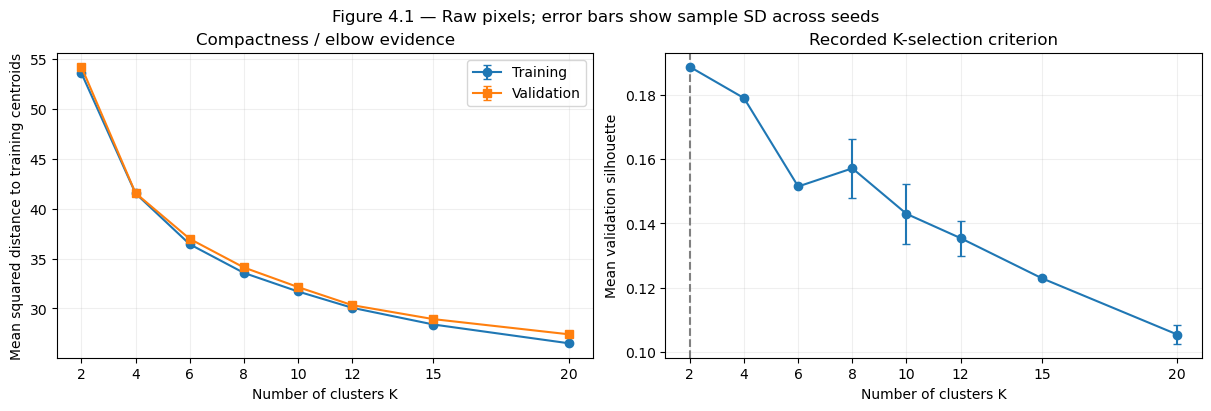

In [52]:
k_records = []
shared_kmeans_settings = { "max_iter": 300, "tol": 1e-4, "algorithm": "lloyd", "copy_x": True,}
shared_config = {
    "preprocessing": "Flatten to 784 pixels and divide by 255",
    "indices_file": str(part4_dir / "used_indices.json"),
    "fixed_kmeans_settings": shared_kmeans_settings,}
with open(part4_dir / "shared_config.json", "w") as file:
    json.dump(shared_config, file, indent=2)
    
for k in K_VALUES:
    for seed in SEEDS:
        record, _ = fit_raw_kmeans( k=k, seed=seed, init="k-means++",
            n_init=10, phase="Ksearch",)
        k_records.append(record)
k_results = pd.DataFrame(k_records)
k_results.to_csv(part4_dir / "k_search_runs.csv", index=False)
k_summary = k_results.groupby("K", as_index=False).agg(
    train_distance_mean=("train_mean_sq_distance", "mean"),
    train_distance_std=("train_mean_sq_distance", "std"),
    val_distance_mean=("val_mean_sq_distance", "mean"),
    val_distance_std=("val_mean_sq_distance", "std"),
    silhouette_mean=("val_silhouette", "mean"),
    silhouette_std=("val_silhouette", "std"),
    valid_silhouette_runs=("val_silhouette", "count"),)

k_summary.to_csv(part4_dir / "k_search_summary.csv", index=False)
print(k_summary.round(4).to_string(index=False))
# Apply the recorded selection rule.
eligible = k_summary.loc[k_summary["valid_silhouette_runs"] == len(SEEDS)]
if eligible.empty:
    raise ValueError("No K produced valid silhouette scores for all seeds.")
chosen_k = int(eligible.sort_values(
        ["silhouette_mean", "K"], ascending=[False, True]).iloc[0]["K"])
print(f"\nSelected K by mean validation silhouette: {chosen_k}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for prefix, label, marker in [("train", "Training", "o"),("val", "Validation", "s"),]:
    axes[0].errorbar(k_summary["K"],k_summary[f"{prefix}_distance_mean"],
        yerr=k_summary[f"{prefix}_distance_std"],marker=marker, capsize=3,label=label,)

axes[0].set_ylabel("Mean squared distance to training centroids")
axes[0].set_title("Compactness / elbow evidence")
axes[0].legend()
axes[1].errorbar(k_summary["K"],k_summary["silhouette_mean"],
    yerr=k_summary["silhouette_std"],marker="o",capsize=3,)
axes[1].axvline(chosen_k, color="grey", linestyle="--")
axes[1].set_ylabel("Mean validation silhouette")
axes[1].set_title("Recorded K-selection criterion")
for ax in axes:
    ax.set_xlabel("Number of clusters K")
    ax.set_xticks(K_VALUES)
    ax.grid(alpha=0.2)
fig.suptitle("Figure 4.1 — Raw pixels; error bars show sample SD across seeds")
fig.savefig(part4_dir / "k_selection.png", dpi=150)
plt.show()

In [53]:
from itertools import combinations

stability_records = []
assignments = {}
for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed in SEEDS:
            record, val_clusters = fit_raw_kmeans( k=chosen_k, seed=seed,
                init=init, n_init=n_init, phase="stability",)
            stability_records.append(record)
            assignments[(init, n_init, seed)] = val_clusters
stability_results = pd.DataFrame(stability_records)
stability_results.to_csv(part4_dir / "stability_runs.csv", index=False)

ari_records = []
for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed_a, seed_b in combinations(SEEDS, 2):
            ari_records.append({"init": init, "n_init": n_init, "seed_a": seed_a,
                "seed_b": seed_b, "ARI": adjusted_rand_score(
                    assignments[(init, n_init, seed_a)],
                    assignments[(init, n_init, seed_b)],),})
ari_results = pd.DataFrame(ari_records)
ari_results.to_csv(part4_dir / "pairwise_stability_ari.csv", index=False)

stability_summary = stability_results.groupby(["init", "n_init"]).agg(
    inertia_mean=("train_inertia", "mean"),
    inertia_sample_std=("train_inertia", "std"),
    silhouette_mean=("val_silhouette", "mean"),
    silhouette_sample_std=("val_silhouette", "std"),)
ari_summary = ari_results.groupby(["init", "n_init"]).agg(
    pairwise_ARI_mean=("ARI", "mean"),
    pairwise_ARI_min=("ARI", "min"),)
stability_summary = stability_summary.join(ari_summary)
stability_summary.to_csv(part4_dir / "stability_summary.csv")

print(stability_summary.round(4).to_string())
print("\nIndividual pairwise ARI values")
print(ari_results.round(4).to_string(index=False))

stability-k2-random-ninit1-seed42: silhouette=0.1888, inertia=160840.70
stability-k2-random-ninit1-seed43: silhouette=0.1887, inertia=160839.72
stability-k2-random-ninit1-seed44: silhouette=0.1888, inertia=160840.72
stability-k2-random-ninit10-seed42: silhouette=0.1887, inertia=160839.72
stability-k2-random-ninit10-seed43: silhouette=0.1887, inertia=160839.59
stability-k2-random-ninit10-seed44: silhouette=0.1887, inertia=160839.73
stability-k2-k-means++-ninit1-seed42: silhouette=0.1888, inertia=160840.72
stability-k2-k-means++-ninit1-seed43: silhouette=0.1888, inertia=160840.70
stability-k2-k-means++-ninit1-seed44: silhouette=0.1888, inertia=160840.72
stability-k2-k-means++-ninit10-seed42: silhouette=0.1887, inertia=160839.73
stability-k2-k-means++-ninit10-seed43: silhouette=0.1887, inertia=160839.73
stability-k2-k-means++-ninit10-seed44: silhouette=0.1887, inertia=160839.72
                  inertia_mean  inertia_sample_std  silhouette_mean  silhouette_sample_std  pairwise_ARI_mean  p

<b>**** Task 4.1 - Choosing K and stability - My Analysis ****</b>
* Figure 4.1 shows squared distances falling sharply from K=2 to K=4, then more slowly. Training and validation distances remain close, with a broad bend around K=4 to 6 than the usual elbow-like graph.
* I selected K=2 because it had the highest mean validation silhouette, 0.1887. Larger K produced more compact clusters but lower silhouette scores. Error bars show variation across seeds, particularly at K=8, 10, 12.
* At K=2, random initialisation was already stable with one restart: pairwise ARI ranged from 0.9761 to 1.0000. Ten restarts increased mean ARI from 0.9841 to 0.9973.
* More restarts gave only a small reduction in inertia. For K-means++, mean inertia fell by about 1 out of 160,841, while silhouette changed from 0.1888 to 0.1887. The measures assess different properties

In [54]:
#k-means++ with ten restarts and lowest-training-inertia seed
#this model will be used in 4.2 to inspect class composition and the comparison required in Part 5
candidates = stability_results.loc[(stability_results["init"] == "k-means++")
    & (stability_results["n_init"] == 10)]

selected_run = candidates.sort_values(["train_inertia", "seed"]).iloc[0]
selected_seed = int(selected_run["seed"])
# Recreate the selected fit using the same data and settings.
kmeans_selected = KMeans( n_clusters=int(chosen_k),init="k-means++",
    n_init=10,random_state=selected_seed,**shared_kmeans_settings,)
kmeans_selected.fit(X_cluster_train)

# Save just this model.
selected_model_path = part4_dir / "selected_kmeans.joblib"
joblib.dump(kmeans_selected, selected_model_path)
# Keep this record: Part 4.2 uses it to locate the selected model.
selection = { "K": int(chosen_k), "init": "k-means++","n_init": 10,
    "seed": selected_seed,
    "representative_rule": "Minimum training inertia among k-means++ runs with 10 restarts",
    "model_path": str(selected_model_path),}

with open(part4_dir / "selected_protocol.json", "w") as file:
    json.dump(selection, file, indent=2)
print(selection)

exp_raw_kmeans = { "id": "P4_1-RAW-KMEANS-01",
    "question": (
        "Which K is good for raw-pixel training, and how sensitive is the solution to initialisation and restarts?"),
    "hypothesis": ("Increasing K will reduce squared-distance distortion. "
        "K-means++ and additional restarts may improve the objective "
        "and reduce sensitivity to initialisation."),
    "changed_variable": (f"K={K_VALUES}; at selected K, init=random/k-means++ and n_init=1/10"),
    "fixed_conditions": ("raw float32 pixels / 255; 784 features;  "
        "Euclidean geometry; Lloyd algorithm; max_iter=300; tol=1e-4"),
    "split": "3,000 training images; 1,000 validation images",
    "seed": str(SEEDS),
    "configuration": ("K search: k-means++, n_init=10; choose highest mean validation "
        "silhouette with smaller K breaking exact ties"),
    "metric": ("Training inertia; training/validation mean squared distance; "
        "validation silhouette; pairwise validation-assignment ARI; sample SD across seeds;"),
    "result": (f"Selected K={chosen_k}; representative seed={selection['seed']}. "
        + stability_summary.reset_index().to_json(orient="records")),
    "output_path": str(part4_dir),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_raw_kmeans])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_raw_kmeans["result"])


{'K': 2, 'init': 'k-means++', 'n_init': 10, 'seed': 44, 'representative_rule': 'Minimum training inertia among k-means++ runs with 10 restarts', 'model_path': 'results/part4_1/selected_kmeans.joblib'}
Selected K=2; representative seed=44. [{"init":"k-means++","n_init":1,"inertia_mean":160840.7135416667,"inertia_sample_std":0.009021098,"silhouette_mean":0.1887971461,"silhouette_sample_std":0.0,"pairwise_ARI_mean":1.0,"pairwise_ARI_min":1.0},{"init":"k-means++","n_init":10,"inertia_mean":160839.7291666667,"inertia_sample_std":0.009021098,"silhouette_mean":0.1886642873,"silhouette_sample_std":0.0,"pairwise_ARI_mean":1.0,"pairwise_ARI_min":1.0},{"init":"random","n_init":1,"inertia_mean":160840.3802083333,"inertia_sample_std":0.5728929919,"silhouette_mean":0.1887528598,"silhouette_sample_std":0.000076706,"pairwise_ARI_mean":0.9840800775,"pairwise_ARI_min":0.9761201163},{"init":"random","n_init":10,"inertia_mean":160839.6822916667,"inertia_sample_std":0.0770762947,"silhouette_mean":0.1886856

<b>** 4.2 - My  plan **<b>
* Examine what the two clusters (since K=2) contain, then connect those observations to how K-means measures similarity.

In [55]:
part4_2_dir = Path("results/part4_2")
part4_2_dir.mkdir(parents=True, exist_ok=True)

with open(part4_dir / "selected_protocol.json") as file:
    selection = json.load(file)
kmeans_selected = joblib.load(selection["model_path"])
chosen_k = int(selection["K"])
# reconstructing validation inputs from the exact indices saved in 4.1.
with open(part4_dir / "used_indices.json", "r") as f:
    saved = json.load(f)
interpretation_index = np.array(saved["val_index"], dtype=int)
X_interpret = (images[interpretation_index].astype(np.float32).reshape(-1, 784) / 255.0)

# labels are used here to interpret the fixed assignments.
true_classes = classes[interpretation_index]
cluster_assignments = kmeans_selected.predict(X_interpret)
composition = pd.crosstab(
    pd.Series(cluster_assignments, name="Cluster"),
    pd.Series(true_classes, name="Class"),).reindex(
    index=range(chosen_k), columns=range(len(class_names)),fill_value=0,)
composition.columns = pd.Index(class_names, name="Class")
print("\nClass counts")
print(composition.to_string())
cluster_sizes = composition.sum(axis=1)
class_supports = composition.sum(axis=0)
print("Validation images per cluster")
print(cluster_sizes.to_string())

# Each row sums to 100% for an occupied cluster.
within_cluster_pct = (composition.div(cluster_sizes.replace(0, np.nan), axis=0) * 100)
print("\nClass composition within each cluster (%)")
print(within_cluster_pct.round(1).to_string())
# Each column sums to 100% for a represented clothing class.
within_class_pct = (composition.div(class_supports.replace(0, np.nan), axis=1) * 100)
print("\nDistribution of each class across clusters (%)")
print(within_class_pct.round(1).to_string())


Class counts
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Cluster                                                                                      
0                 76       73        77     63    90       0     65        0   35          13
1                 24       27        23     37    10     100     35      100   65          87
Validation images per cluster
Cluster
0    492
1    508

Class composition within each cluster (%)
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Cluster                                                                                       
0               15.4     14.8      15.7   12.8  18.3     0.0   13.2      0.0   7.1         2.6
1                4.7      5.3       4.5    7.3   2.0    19.7    6.9     19.7  12.8        17.1

Distribution of each class across clusters (%)
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag 

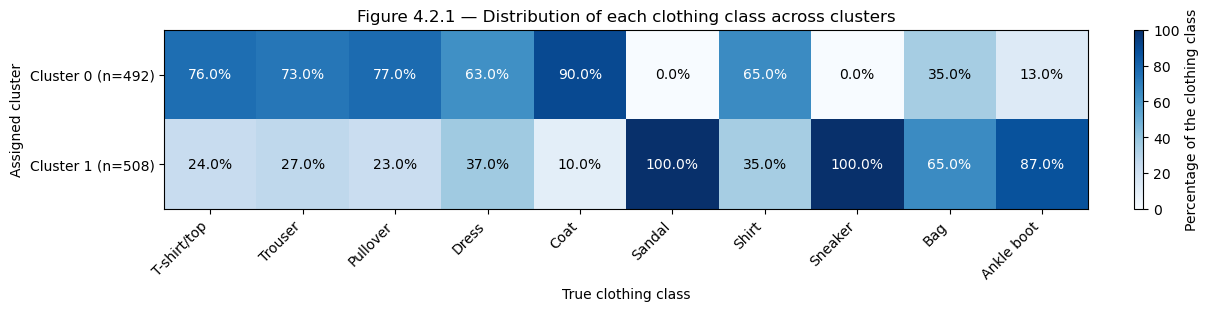

In [56]:
#showing the class distribution using a heatmap
fig, ax = plt.subplots(figsize=(12, max(3, chosen_k * 0.8)),layout="constrained",)
heatmap = ax.imshow(within_class_pct.to_numpy(),cmap="Blues",vmin=0,vmax=100,aspect="auto",)

ax.set_xticks(range(len(class_names)), labels=class_names)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticks(range(chosen_k),labels=[
        f"Cluster {c} (n={cluster_sizes.loc[c]})" for c in range(chosen_k)],)

for cluster in range(chosen_k):
    for class_id in range(len(class_names)):
        value = within_class_pct.iloc[cluster, class_id]
        ax.text( class_id, cluster, f"{value:.1f}%",
            ha="center", va="center", color="white" if value > 50 else "black",)
ax.set_title("Figure 4.2.1 — Distribution of each clothing class across clusters")
ax.set_xlabel("True clothing class")
ax.set_ylabel("Assigned cluster")
fig.colorbar(heatmap, ax=ax, label="Percentage of the clothing class")
fig.savefig(part4_2_dir / "class_distribution.png",dpi=150,bbox_inches="tight",)
plt.show()

<b>** 4.2 - Interim analysis ** </b>
* Cluster 0 contained 492 images, mostly body clothing. It received 90% of coats, but coats made up only 18.3% of the cluster.
* Cluster 1 contained 508 images, including all sandals and sneakers and 87% of ankle boots. Footwear was 56.5%; other classes were also present.
* Shirts, dresses and bags were split across both clusters.

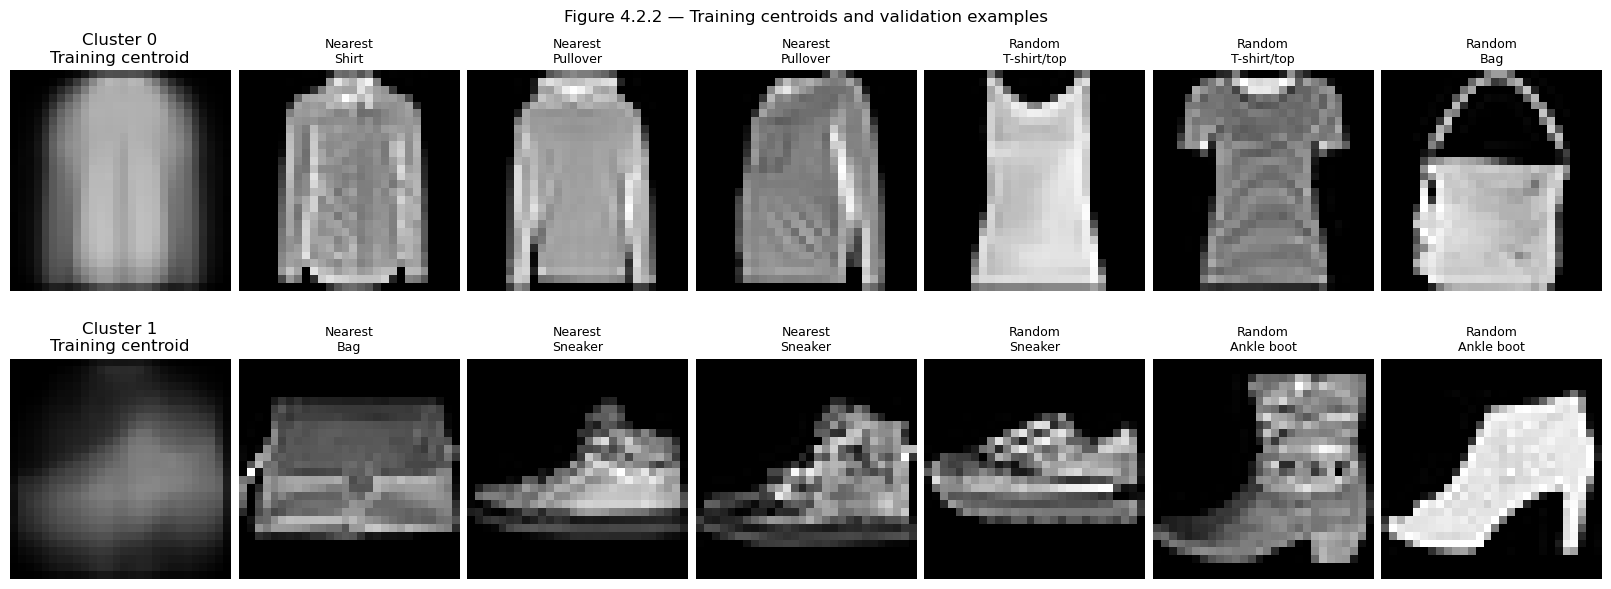

In [57]:
# Centroids and example images
distances = kmeans_selected.transform(X_interpret)
rng = np.random.default_rng(42)
fig, axes = plt.subplots(chosen_k, 7, figsize=(16, 3 * chosen_k), 
    squeeze=False,layout="constrained",)

example_records = []
for cluster in range(chosen_k):
    for ax in axes[cluster]:
        ax.axis("off")
    axes[cluster, 0].imshow(kmeans_selected.cluster_centers_[cluster].reshape(28, 28),
        cmap="gray",vmin=0,vmax=1,)
    axes[cluster, 0].set_title(f"Cluster {cluster}\nTraining centroid")

    members = np.flatnonzero(cluster_assignments == cluster)
    nearest = members[np.argsort(distances[members, cluster])[:3]]
    remaining = np.setdiff1d(members, nearest)
    random_members = rng.choice(remaining,size=min(3, len(remaining)),replace=False,)

    for start_column, positions, method in [(1, nearest, "Nearest"),(4, random_members, "Random"),]:
        for offset, position in enumerate(positions):
            ax = axes[cluster, start_column + offset]
            original_index = int(interpretation_index[position])
            ax.imshow(images[original_index],cmap="gray", vmin=0,vmax=255,)
            ax.set_title(f"{method}\n{class_names[true_classes[position]]}",fontsize=9,)
            example_records.append({"cluster": cluster,"selection": method,
                "official_train_index": original_index,
                "true_class": class_names[true_classes[position]],
                "distance_to_centroid": distances[position, cluster],})
fig.suptitle("Figure 4.2.2 — Training centroids and validation examples")
fig.savefig(part4_2_dir / "centroids_and_examples.png",dpi=150,bbox_inches="tight",)
plt.show()

pd.DataFrame(example_records).to_csv(part4_2_dir / "displayed_examples.csv", index=False)

<b>** 4.2 - Finalanalysis **</b>
* In Figure 4.2.2, cluster 0 has a tall, centrally filled centroid. Its nearest examples are a shirt and two pullovers.
* Cluster 1 has a shoe-like centroid. Its nearest examples include two sneakers and a bag; random examples include sneakers and ankle boots.
* Bags appear in both clusters, showing that pixel patterns can cross class boundaries.
* Comparing the figure and the table earlier, they indicate grouping by broad shape and foreground position.

In [58]:
with open(part4_dir / "selected_protocol.json", "r") as f:
    p42_selection = json.load(f)

exp_raw_cluster_interpret = { "id": "P4_2-RAW_CLUSTER_INTERPRET",
    "question": "What clothing categories are seen in the fixed raw-pixel clusters?",
    "hypothesis": "Raw-pixel clusters will only  capture broad silhouette similarities mixing the classes.",
    "changed_variable": "None: interpreting the protocol fixed in Part 4.1.",
    "fixed_conditions": "Same selected K-means model and validation images; labels added to interpret",
    "split": "Model fitted on 3,000 training images; interpretation on 1,000 validation images.",
    "seed": (f"selected_kmeans_seed: {p42_selection["seed"]}, example_sampling_seed: 42"),
    "configuration": ("images: 784 raw pixels divided by 255; ",
        f"selected_protocol: {p42_selection}; ",),
    "metric": "Cluster sizes; class composition and distribution; ",
    "result": ("footwear_dominated_cluster; size: 508, footwear: 287; "
            "body_clothing: 156, bags: 65; clothing_dominated_cluster_size: 492; "
        "conclusion: Broad clothing-footwear grouping with a lot of mixed classes"),
    "output_path": (f"selected_model: {p42_selection["model_path"]}; ",
        f"selected_protocol: {str(part4_dir / "selected_protocol.json")}"),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_raw_cluster_interpret])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

<b>***** Part 4.3 - how this clustering relates to the classification errors from Part 1.3 *******</b>
* References:
  * Part 1.3 figures - figures/part1_3_error_examples_4_classifiers.png, figures/part1_3_shirt_errors_svm.png
  * Part 4.2 figures - class distribution heatmap here (results/part4_2/class_distribution.png) and the centroids and examples here (centroids_and_examples.png)
* Part 1.3 showed  Shirt is hardest confused with T-shirt/top and Coat. Figure 4.2 places most shirts, tops, pullovers and coats in the same cluster; Figure 4.2.2 shows their visual similarities.
* Shared patterns may be contributing to these errors, but clustering does not prove the cause.
* All sandals and sneakers also share a cluster, although supervised classifiers could distinguish them

<b>** 4.4 - My  plan ** </b>
* Chosing Ward because it merges groups with the smallest increase in squared error, linking it to K-means while showing nested structure.
* Setup: 200 randomly sampled images from the saved clustering training subset, seed 42, Ward linkage and Euclidean distance.

In [59]:
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

hierarchy_dir = Path("results/part4_4")
hierarchy_dir.mkdir(parents=True, exist_ok=True)
HIERARCHY_SEED = 42
HIERARCHY_N = 200

with open(part4_dir / "used_indices.json", "r") as f:
    saved_indices = json.load(f)
training_pool = np.asarray(saved_indices["train_index"], dtype=int)
rng = np.random.default_rng(HIERARCHY_SEED)
hierarchy_indices = np.sort(rng.choice(training_pool, size=HIERARCHY_N, replace=False))
# same raw-pixel representation as task 4.1.
X_hierarchy = (images[hierarchy_indices].astype(np.float64).reshape(HIERARCHY_N, -1) / 255.0)
Z = linkage(X_hierarchy, method="ward", metric="euclidean", optimal_ordering=False,)

# Two different cuts of the SAME fitted hierarchy.
cuts = cut_tree(Z, n_clusters=[2, 4])
groups_2 = cuts[:, 0]
groups_4 = cuts[:, 1]
np.save(hierarchy_dir / "image_indices.npy", hierarchy_indices)
np.save(hierarchy_dir / "linkage_matrix.npy", Z)
config = {"sample_source": str(part4_dir / "used_indices.json"),"sample_source_key": "train_index",
    "sample_size": HIERARCHY_N, "sampling_seed": HIERARCHY_SEED,
    "sampling": "without replacement; indices sorted before fitting",
    "preprocessing": "flatten 28x28 pixels; float64; divide by 255", "method": "ward",
    "metric": "euclidean", "optimal_ordering": False, "interpretation_cuts": [2, 4],}

with open(hierarchy_dir / "configuration.json", "w") as f:
    json.dump(config, f, indent=2)
print(f"Images: {HIERARCHY_N}")
print(f"Features per image: {X_hierarchy.shape[1]}")
print(f"Two-group sizes: {np.bincount(groups_2)}")
print(f"Four-group sizes: {np.bincount(groups_4)}")

Images: 200
Features per image: 784
Two-group sizes: [ 81 119]
Four-group sizes: [28 49 53 70]



Class counts at the 2-group cut:
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                                                                      
0                2        1         5      0     4      18      4       20    9          18
1               24       17        12     19    19       0     19        0    9           0

Composition within each group (%) at the 2-group cut:
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Group                                                                                       
0              2.5      1.2       6.2    0.0   4.9    22.2    4.9     24.7  11.1        22.2
1             20.2     14.3      10.1   16.0  16.0     0.0   16.0      0.0   7.6         0.0

Class counts at the 4-group cut:
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                        

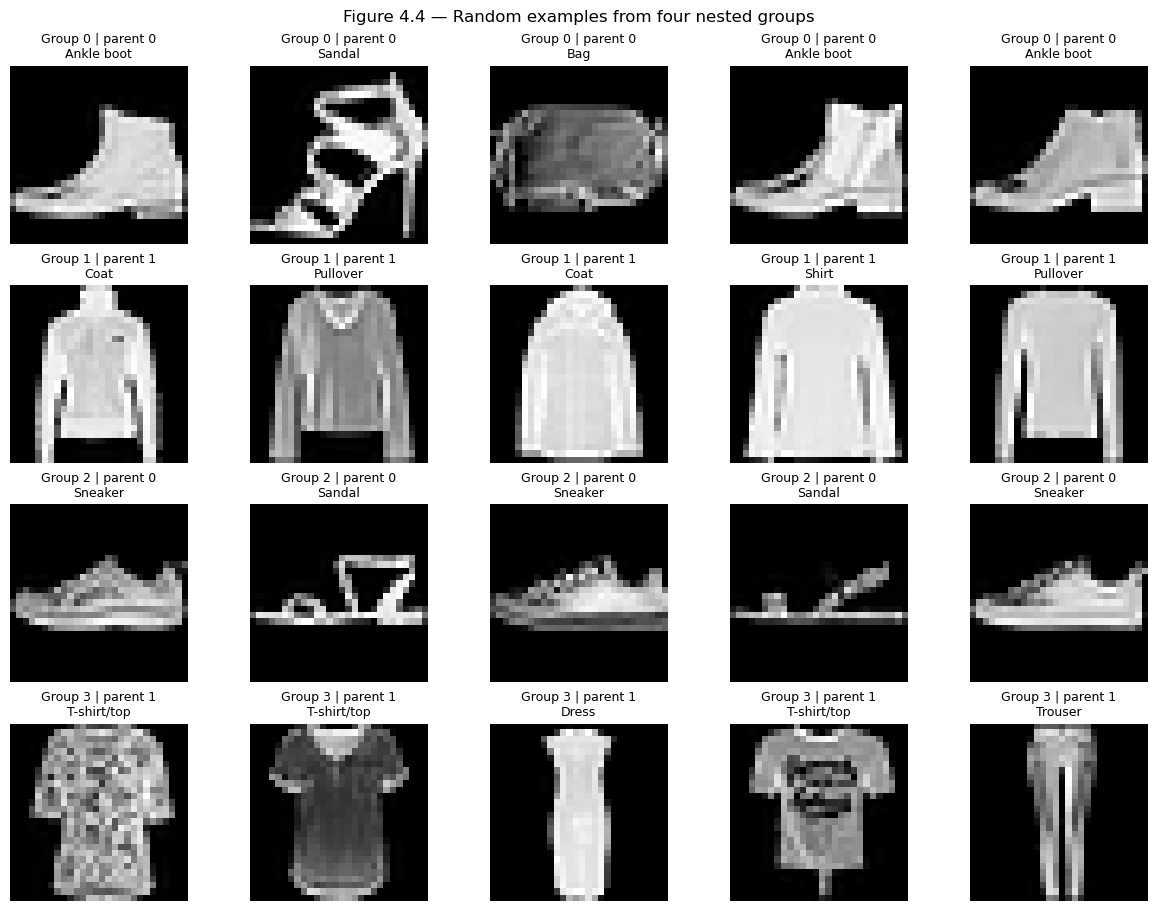

In [60]:
#Interpreting the groups with labels
true_hierarchy = np.asarray(classes)[hierarchy_indices]

assignments = pd.DataFrame({"original_index": hierarchy_indices,"group_2": groups_2,
    "group_4": groups_4,"true_class_id": true_hierarchy,
    "true_class": [class_names[int(c)] for c in true_hierarchy],})
for k, assignments_k in [(2, groups_2), (4, groups_4)]:
    counts = pd.crosstab(
        pd.Series(assignments_k, name="Group"),
        pd.Series(true_hierarchy, name="Class"),).reindex( index=range(k),
        columns=range(len(class_names)),fill_value=0,)
    counts.columns = pd.Index(class_names, name="Class")
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    counts.to_csv(hierarchy_dir / f"class_counts_k{k}.csv")
    percentages.to_csv(hierarchy_dir / f"composition_percent_k{k}.csv")

    print(f"\nClass counts at the {k}-group cut:")
    print(counts.to_string())
    print(f"\nComposition within each group (%) at the {k}-group cut:")
    print(percentages.round(1).to_string())

nested = pd.crosstab(
    pd.Series(groups_4, name="Four-group branch"),
    pd.Series(groups_2, name="Two-group parent"),)
nested.to_csv(hierarchy_dir / "nested_groups.csv")
print("\nHow the four groups sit within the two broader groups:")
print(nested.to_string())

# random examples avoid selecting only particularly convincing images.
example_rng = np.random.default_rng(42)
fig, axes = plt.subplots(4, 5, figsize=(12, 9), layout="constrained")
example_records = []
for group in range(4):
    members = np.flatnonzero(groups_4 == group)
    chosen = example_rng.choice(members, size=min(5, len(members)), replace=False)
    for ax in axes[group]:
        ax.axis("off")
    for column, pos in enumerate(chosen):
        ax = axes[group, column]
        # Image, label and membership all use the SAME subset position.
        ax.imshow(X_hierarchy[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
        parent = int(groups_2[pos])
        original_index = int(hierarchy_indices[pos])
        ax.set_title(f"Group {group} | parent {parent}\n"f"{class_names[int(true_hierarchy[pos])]}",fontsize=9,)
fig.suptitle("Figure 4.4 — Random examples from four nested groups")
fig.savefig(hierarchy_dir / "group_examples.png",dpi=150,bbox_inches="tight",)
plt.show()


<b> ** Task 4.4 - Analysis ** </b>
* Ward produced groups of 81 and 119 images. The smaller group contained all 56 footwear images, alongside 25 other items.
* At four groups, the footwear branch split mostly into ankle boots and bags vs sneakers and sandals. The other branch split into mixed clothing groups.
* The examples shows differences in shape: taller boots vs lower footwear, and long-sleeved garments vs more varied clothing.
* The broad clothing to footwear split resembles K-means

In [61]:
exp_raw_hierarchy = { "id": "P4_4_RAW_HIERARCHY-01",
    "question": "Does hierarchical clustering reveal more cluster beyond the K-means partition?",
    "hypothesis": "Broad groups may contain smaller subgroups with different with different class compositions.",
    "changed_variable": "Inspect two-group and four-group cuts of one Ward hierarchy.",
    "fixed_conditions": "Same 200 images and raw-pixel representation at both cuts; ",
    "split": "200 images sampled from the fixed 3,000-image clustering training subset.",
    "seed": "subset_seed: 42; example_seed: 42",
    "configuration": ("representation: 784 raw pixels; float64; divide by 255; "
        "method: Ward; metric: Euclidean; optimal_ordering: False; cuts: [2, 4]"),
     "metric": "group sizes; nested memberships; class composition",
    "result": "two_group_sizes: [81, 119]; four_group_sizes: [28, 49, 53, 70]",
    "conclusion": ("Both broad branches divide at the four-group cut. "
            "The footwear-containing branch separates mainly ankle boots "
            "and bags from mainly sneakers and sandals. "
            "The other branch divides mixed clothing groups."),
    "output_path": f"{str(hierarchy_dir)}",}


register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_raw_hierarchy])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_raw_hierarchy["result"])

two_group_sizes: [81, 119]; four_group_sizes: [28, 49, 53, 70]


<b> ** 5.1 - My plan ** </b>
* Replace 784 raw pixels with 256 hidden activations from the frozen, selected MLP. Keep the same images and clustering settings.
* Repeat the K-search using the same three seeds and selection rule keeping the main comparison at K=2 so only the representation changes.
* Repeat the stability checks, then compare class composition and examples exactly like above cases
* Also repeat Ward clustering on the same 200 images, using the same two and four group cuts


In [62]:
#load and freeze the MLP
checkpoint_path = Path("results/part3/P3-w256-e500-l0.01-dropout-seed42.pt")
checkpoint = torch.load(checkpoint_path,map_location="cpu",weights_only=True,)
feature_model = RegularisedMLP(width=checkpoint["width"],dropout=checkpoint["dropout"],)
feature_model.load_state_dict(checkpoint["model_state"])
feature_model = feature_model.to(device)

# disable dropout and prevent parameter updates.
feature_model.eval()
feature_model.requires_grad_(False)
print("Checkpoint:", checkpoint_path)
print("Selected epoch:", checkpoint["epoch"])
print("Hidden units:", checkpoint["width"])
print("Training dropout:", checkpoint["dropout"])
print("Evaluation mode:", not feature_model.training)
print("All parameters frozen:",
    all(not p.requires_grad for p in feature_model.parameters()),)

Checkpoint: results/part3/P3-w256-e500-l0.01-dropout-seed42.pt
Selected epoch: 451
Hidden units: 256
Training dropout: 0.2
Evaluation mode: True
All parameters frozen: True


In [63]:
#relod the indices used in part4
with open(part4_dir / "used_indices.json", "r") as f:
    part4_indices = json.load(f)
feature_train_indices = np.asarray(part4_indices["train_index"], dtype=int)
feature_val_indices = np.asarray(part4_indices["val_index"], dtype=int)

def scaled_pixels(indices):
    return (images[indices].astype(np.float32).reshape(len(indices), -1) / 255.0)
# keep these arrays for the raw-pixel comparison.
raw_train = scaled_pixels(feature_train_indices)
raw_val = scaled_pixels(feature_val_indices)
print("Raw training shape:", raw_train.shape)
print("Raw validation shape:", raw_val.shape)

#extract hidden activation
def extract_hidden_features(pixel_array, batch_size=256):
    feature_model.eval()
    batches = []
    for start in range(0, len(pixel_array), batch_size):
        pixels = torch.from_numpy(pixel_array[start:start + batch_size]).to(device)
        features = torch.relu(feature_model.hidden(pixels))
        batches.append(features.cpu().numpy())
    return np.concatenate(batches, axis=0)

mlp_train_features = extract_hidden_features(raw_train)
mlp_val_features = extract_hidden_features(raw_val)
print("MLP training feature shape:", mlp_train_features.shape)
print("MLP validation feature shape:", mlp_val_features.shape)
print("Additional feature transformation: none")

Raw training shape: (3000, 784)
Raw validation shape: (1000, 784)
MLP training feature shape: (3000, 256)
MLP validation feature shape: (1000, 256)
Additional feature transformation: none


In [64]:
#KMeans search on these MLP features
K_VALUES = [2, 4, 6, 8, 10, 12, 15, 20]
CLUSTER_SEEDS = [42, 43, 44]

mlp_search_records = []
for k in K_VALUES:
    for seed in CLUSTER_SEEDS:
        model = KMeans(n_clusters=k,init="k-means++",n_init=10,max_iter=300,
            tol=1e-4,algorithm="lloyd",copy_x=True,random_state=seed,)
        # fit only on training features.
        model.fit(mlp_train_features)
        val_clusters = model.predict(mlp_val_features)
        occupied = len(np.unique(val_clusters))
        silhouette = (silhouette_score(mlp_val_features, val_clusters)
            if 1 < occupied < len(mlp_val_features) else np.nan)

        mlp_search_records.append({"K": k,"seed": seed,"init": "k-means++",
            "n_init": 10,"inertia": model.inertia_,
            "train_distance": (model.inertia_ / len(mlp_train_features)),
            "val_distance": (-model.score(mlp_val_features) / len(mlp_val_features)),
            "silhouette": silhouette,"occupied_val_clusters": occupied,"iterations": model.n_iter_,})
        print(f"MLP features: K={k}, seed={seed}, silhouette={silhouette:.4f}, "
            f"inertia={model.inertia_:.2f}")
mlp_search_results = pd.DataFrame(mlp_search_records)

MLP features: K=2, seed=42, silhouette=0.3360, inertia=102847.70
MLP features: K=2, seed=43, silhouette=0.3360, inertia=102847.70
MLP features: K=2, seed=44, silhouette=0.3360, inertia=102847.70
MLP features: K=4, seed=42, silhouette=0.2241, inertia=78460.37
MLP features: K=4, seed=43, silhouette=0.2240, inertia=78459.91
MLP features: K=4, seed=44, silhouette=0.2240, inertia=78459.91
MLP features: K=6, seed=42, silhouette=0.2503, inertia=62463.40
MLP features: K=6, seed=43, silhouette=0.2503, inertia=62464.20
MLP features: K=6, seed=44, silhouette=0.2500, inertia=62463.70
MLP features: K=8, seed=42, silhouette=0.2530, inertia=53203.59
MLP features: K=8, seed=43, silhouette=0.2531, inertia=53203.79
MLP features: K=8, seed=44, silhouette=0.2531, inertia=53202.40
MLP features: K=10, seed=42, silhouette=0.2461, inertia=48055.29
MLP features: K=10, seed=43, silhouette=0.2463, inertia=48054.71
MLP features: K=10, seed=44, silhouette=0.2463, inertia=48054.67
MLP features: K=12, seed=42, silho

In [65]:
#summarize across seeds and apply same selection rule
part5_1_dir = Path("results/part5_1")
part5_1_dir.mkdir(parents=True, exist_ok=True)

mlp_k_summary = (mlp_search_results.groupby("K", as_index=False).agg(
        train_distance_mean=("train_distance", "mean"),
        train_distance_std=("train_distance", "std"),
        val_distance_mean=("val_distance", "mean"),
        val_distance_std=("val_distance", "std"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),
        valid_silhouette_runs=("silhouette", "count"),))
# require a valid silhouette for all three seeds.
eligible = mlp_k_summary.loc[mlp_k_summary["valid_silhouette_runs"] == len(CLUSTER_SEEDS)]
if eligible.empty:
    raise ValueError("No K had valid silhouette scores for all seeds.")

mlp_selected_k = int(eligible.sort_values(["silhouette_mean", "K"],
        ascending=[False, True],).iloc[0]["K"])
mlp_k_summary_results = pd.DataFrame(mlp_k_summary)
mlp_k_summary_results.to_csv(part5_1_dir / "mlp_k_summary.csv", index=False)
print(mlp_k_summary.round(4).to_string(index=False))
print("\nSelected K for MLP features:", mlp_selected_k)
print("K retained for the main raw-versus-MLP comparison: 2")

 K  train_distance_mean  train_distance_std  val_distance_mean  val_distance_std  silhouette_mean  silhouette_std  valid_silhouette_runs
 2              34.2826              0.0000            34.5182            0.0000           0.3360          0.0000                      3
 4              26.1534              0.0001            26.5208            0.0008           0.2240          0.0001                      3
 6              20.8213              0.0001            20.8340            0.0046           0.2502          0.0002                      3
 8              17.7344              0.0003            17.7225            0.0024           0.2531          0.0001                      3
10              16.0183              0.0001            16.1382            0.0028           0.2462          0.0001                      3
12              15.1154              0.0066            15.3091            0.1259           0.2096          0.0017                      3
15              14.1023              0.01

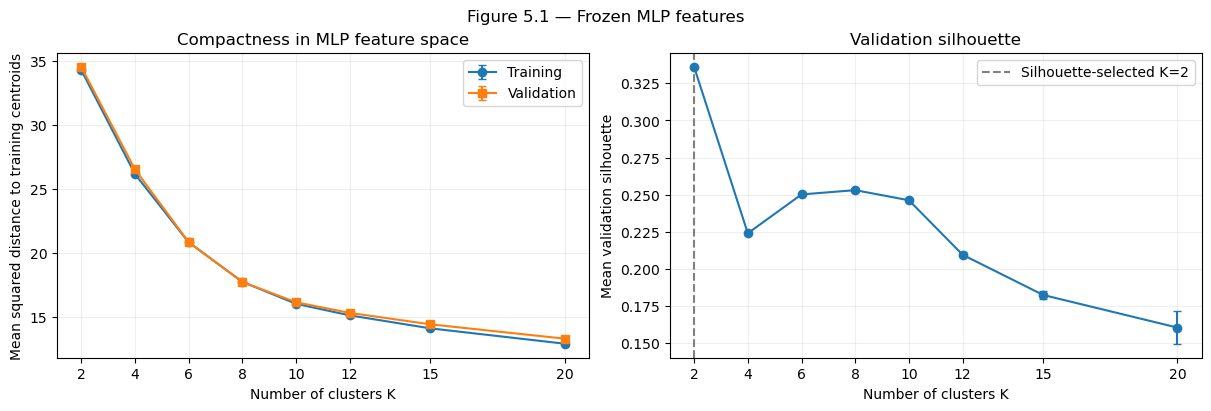

In [66]:
#plot the results
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for split, marker in [("train", "o"), ("val", "s")]:
    axes[0].errorbar(mlp_k_summary["K"],mlp_k_summary[f"{split}_distance_mean"],
        yerr=mlp_k_summary[f"{split}_distance_std"],marker=marker,
        capsize=3,label={"train": "Training", "val": "Validation"}[split],)

axes[0].set_title("Compactness in MLP feature space")
axes[0].set_ylabel("Mean squared distance to training centroids")
axes[0].legend()
axes[1].errorbar(mlp_k_summary["K"],mlp_k_summary["silhouette_mean"],
    yerr=mlp_k_summary["silhouette_std"],marker="o",capsize=3,)
axes[1].axvline(mlp_selected_k,color="gray",linestyle="--",
    label=f"Silhouette-selected K={mlp_selected_k}",)
axes[1].set_title("Validation silhouette")
axes[1].set_ylabel("Mean validation silhouette")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Number of clusters K")
    ax.set_xticks(K_VALUES)
    ax.grid(alpha=0.2)
fig.suptitle("Figure 5.1 — Frozen MLP features")
fig.savefig(part5_1_dir / "frozen_mlp_features.png",dpi=150,)
plt.show()

<b> ** 5.1 - Interim analysis ** <b>
* The MLP features gave higher validation silhouette at every tested K. At K=2, it increased from 0.1887 to 0.3360, showing stronger relative separation.
* Squared distances decreased as K increased, but silhouette remained highest at K=2. Error bars show variation across three seeds.
* Higher silhouette does not mean better class grouping; composition and examples must also be checked.

In [67]:
#stabilty experiment with K=2
COMPARISON_K = 2
mlp_stability_records = []
mlp_stability_assignments = {}

# retaining only the representative model for later interpretation.
mlp_kmeans_selected = None
mlp_selected_seed = None
best_representative_inertia = float("inf")

for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed in CLUSTER_SEEDS:
            model = KMeans(n_clusters=COMPARISON_K,init=init,n_init=n_init,
                max_iter=300,tol=1e-4,algorithm="lloyd",copy_x=True,random_state=seed,)
            model.fit(mlp_train_features)
            val_clusters = model.predict(mlp_val_features)
            occupied = len(np.unique(val_clusters))
            silhouette = (silhouette_score(mlp_val_features, val_clusters)
                if 1 < occupied < len(mlp_val_features) else np.nan)

            mlp_stability_assignments[(init, n_init, seed)] = val_clusters
            mlp_stability_records.append({"K": COMPARISON_K, "init": init, "n_init": n_init,
                "seed": seed,"inertia": model.inertia_, "silhouette": silhouette,"iterations": model.n_iter_,})
            # aame representative-selection rule as Part 4:
            # lowest training inertia among k-means++, n_init=10.
            # resolve an exact tie using the smaller seed.
            if init == "k-means++" and n_init == 10:
                if ( mlp_kmeans_selected is None or (model.inertia_, seed)
                    < (best_representative_inertia, mlp_selected_seed)):
                    mlp_kmeans_selected = model
                    mlp_selected_seed = seed
                    best_representative_inertia = model.inertia_
            print(
                f"MLP stability: K={COMPARISON_K}, init={init}, n_init={n_init}, seed={seed}: "
                f"silhouette={silhouette:.4f}, inertia={model.inertia_:.2f}")
mlp_stability_results = pd.DataFrame(mlp_stability_records)

MLP stability: K=2, init=random, n_init=1, seed=42: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=1, seed=43: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=1, seed=44: silhouette=0.3360, inertia=102847.67
MLP stability: K=2, init=random, n_init=10, seed=42: silhouette=0.3360, inertia=102847.68
MLP stability: K=2, init=random, n_init=10, seed=43: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=random, n_init=10, seed=44: silhouette=0.3360, inertia=102847.68
MLP stability: K=2, init=k-means++, n_init=1, seed=42: silhouette=0.3360, inertia=102848.70
MLP stability: K=2, init=k-means++, n_init=1, seed=43: silhouette=0.3360, inertia=102847.68
MLP stability: K=2, init=k-means++, n_init=1, seed=44: silhouette=0.3360, inertia=102847.68
MLP stability: K=2, init=k-means++, n_init=10, seed=42: silhouette=0.3360, inertia=102847.69
MLP stability: K=2, init=k-means++, n_init=10, seed=43: silhouette=0.3360, inertia=102847.69
M

In [68]:
#compare assignments across seeds
from itertools import combinations 

mlp_ari_records = []
for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        for seed_a, seed_b in combinations(CLUSTER_SEEDS, 2):
            ari = adjusted_rand_score(
                mlp_stability_assignments[(init, n_init, seed_a)],
                mlp_stability_assignments[(init, n_init, seed_b)],)
            mlp_ari_records.append({"init": init,"n_init": n_init,"seed_a": seed_a,
                "seed_b": seed_b,"ARI": ari,})

mlp_pairwise_ari = pd.DataFrame(mlp_ari_records)
mlp_stability_summary = (
    mlp_stability_results.groupby(["init", "n_init"]).agg(
        inertia_mean=("inertia", "mean"),inertia_sample_std=("inertia", "std"),
        silhouette_mean=("silhouette", "mean"),
        silhouette_sample_std=("silhouette", "std"),)
    .join(mlp_pairwise_ari.groupby(["init", "n_init"]).agg(
            pairwise_ARI_mean=("ARI", "mean"),pairwise_ARI_min=("ARI", "min"),)))
mlp_stability_summary.to_csv(part5_1_dir / "stability_summary.csv", index=False)
print("\nMLP-feature stability summary")
print(mlp_stability_summary.round(4).to_string())
print("\nIndividual pairwise ARI values")
print(mlp_pairwise_ari.round(4).to_string(index=False))
print("\nRepresentative model for interpretation:")
print( f"K={COMPARISON_K}, init=k-means++, n_init=10, seed={mlp_selected_seed}")


MLP-feature stability summary
                  inertia_mean  inertia_sample_std  silhouette_mean  silhouette_sample_std  pairwise_ARI_mean  pairwise_ARI_min
init      n_init                                                                                                               
k-means++ 1        102848.0208              0.5909            0.336                    0.0                1.0               1.0
          10       102847.6875              0.0000            0.336                    0.0                1.0               1.0
random    1        102847.6823              0.0090            0.336                    0.0                1.0               1.0
          10       102847.6823              0.0045            0.336                    0.0                1.0               1.0

Individual pairwise ARI values
     init  n_init  seed_a  seed_b  ARI
   random       1      42      43  1.0
   random       1      42      44  1.0
   random       1      43      44  1.0
   random    

In [69]:
#compare class composition
# load the selected raw-pixel model from Part 4.
with open(part4_dir / "selected_protocol.json", "r") as f:
    raw_selection = json.load(f)
raw_kmeans_selected = joblib.load(raw_selection["model_path"])
with open(part4_dir / "used_indices.json", "r") as f:
    saved_indices = json.load(f)
true_feature_val = np.asarray(classes)[feature_val_indices]
raw_assignments = raw_kmeans_selected.predict(raw_val)
mlp_assignments = mlp_kmeans_selected.predict(mlp_val_features)

def composition_tables(assignments):
    counts = pd.crosstab(
        pd.Series(assignments, name="Cluster"),
        pd.Series(true_feature_val, name="Class"),).reindex(index=range(2),
        columns=range(len(class_names)),fill_value=0,)
    counts.columns = pd.Index(class_names, name="Class")
    # each row sums to 100%: what is inside this cluster?
    within_cluster = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
    # each column sums to 100%: where did this class go?
    within_class = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1) * 100

    return counts, within_cluster, within_class

raw_counts, raw_cluster_pct, raw_class_pct = composition_tables(raw_assignments)
mlp_counts, mlp_cluster_pct, mlp_class_pct = composition_tables(mlp_assignments)
for name, counts, cluster_pct, class_pct in [
    ("Raw pixels", raw_counts, raw_cluster_pct, raw_class_pct),
    ("MLP features", mlp_counts, mlp_cluster_pct, mlp_class_pct),]:
    print(f"\n{name}: validation images per cluster")
    print(counts.sum(axis=1).to_string())
    print(f"\n{name}: class counts")
    print(counts.to_string())
    print(f"\n{name}: composition within each cluster (%)")
    print(cluster_pct.round(1).to_string())
    print(f"\n{name}: distribution of each class across clusters (%)")
    print(class_pct.round(1).to_string())


Raw pixels: validation images per cluster
Cluster
0    492
1    508

Raw pixels: class counts
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Cluster                                                                                      
0                 76       73        77     63    90       0     65        0   35          13
1                 24       27        23     37    10     100     35      100   65          87

Raw pixels: composition within each cluster (%)
Class    T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Cluster                                                                                       
0               15.4     14.8      15.7   12.8  18.3     0.0   13.2      0.0   7.1         2.6
1                4.7      5.3       4.5    7.3   2.0    19.7    6.9     19.7  12.8        17.1

Raw pixels: distribution of each class across clusters (%)
Class    T-shirt/top  Trouser  Pullover 

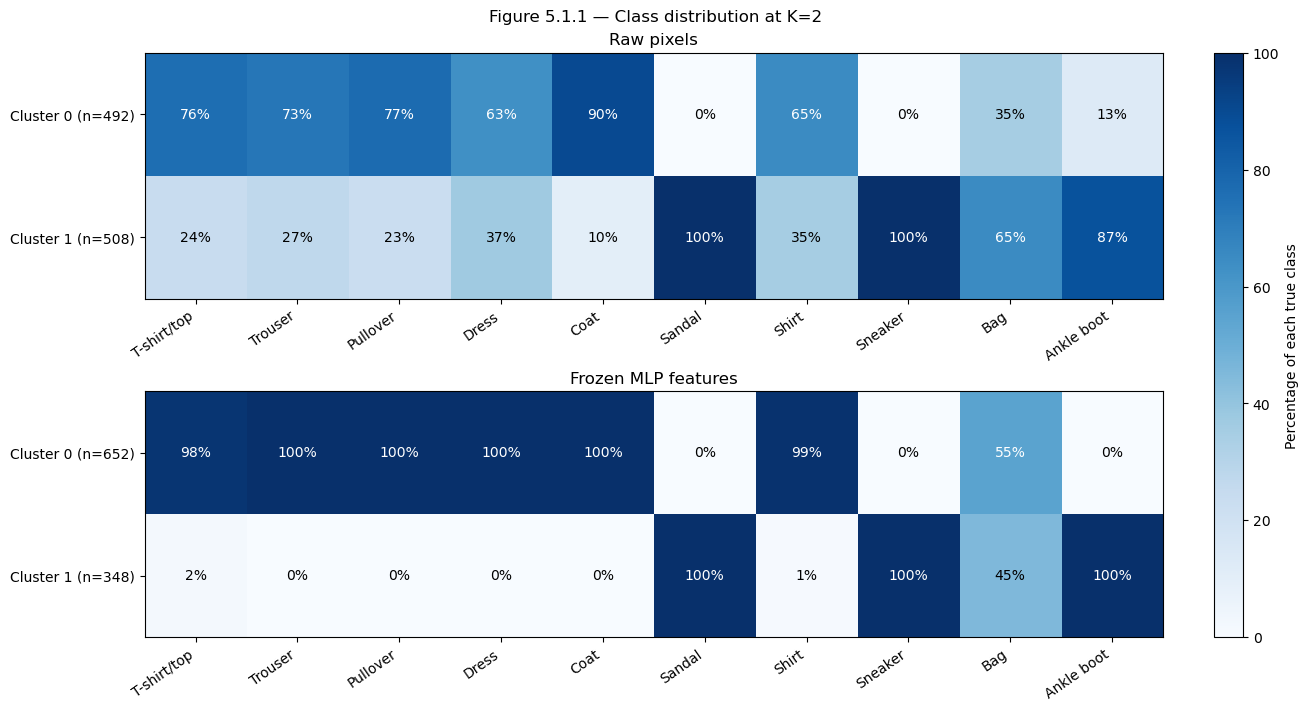

In [70]:
#plot ths comparison
#can be added to the top cell as one
fig, axes = plt.subplots(2, 1, figsize=(13, 7), layout="constrained")

for ax, name, percentages, counts in [(axes[0], "Raw pixels", raw_class_pct, raw_counts),
    (axes[1], "Frozen MLP features", mlp_class_pct, mlp_counts),]:
    im = ax.imshow(percentages.to_numpy(),cmap="Blues",vmin=0,
        vmax=100,aspect="auto",)
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=35, ha="right")
    ax.set_yticks(range(2))
    ax.set_yticklabels([f"Cluster {c} (n={int(counts.loc[c].sum())})" for c in range(2)])
    ax.set_title(name)

    for row in range(2):
        for col in range(len(class_names)):
            value = percentages.iloc[row, col]
            ax.text(col, row, f"{value:.0f}%",ha="center",va="center",
                color="white" if value > 50 else "black",)

fig.colorbar(im, ax=axes.tolist(),label="Percentage of each true class",)
fig.suptitle("Figure 5.1.1 — Class distribution at K=2")
fig.savefig(part5_1_dir / "class_distribution.png",dpi=150,bbox_inches="tight",)
plt.show()

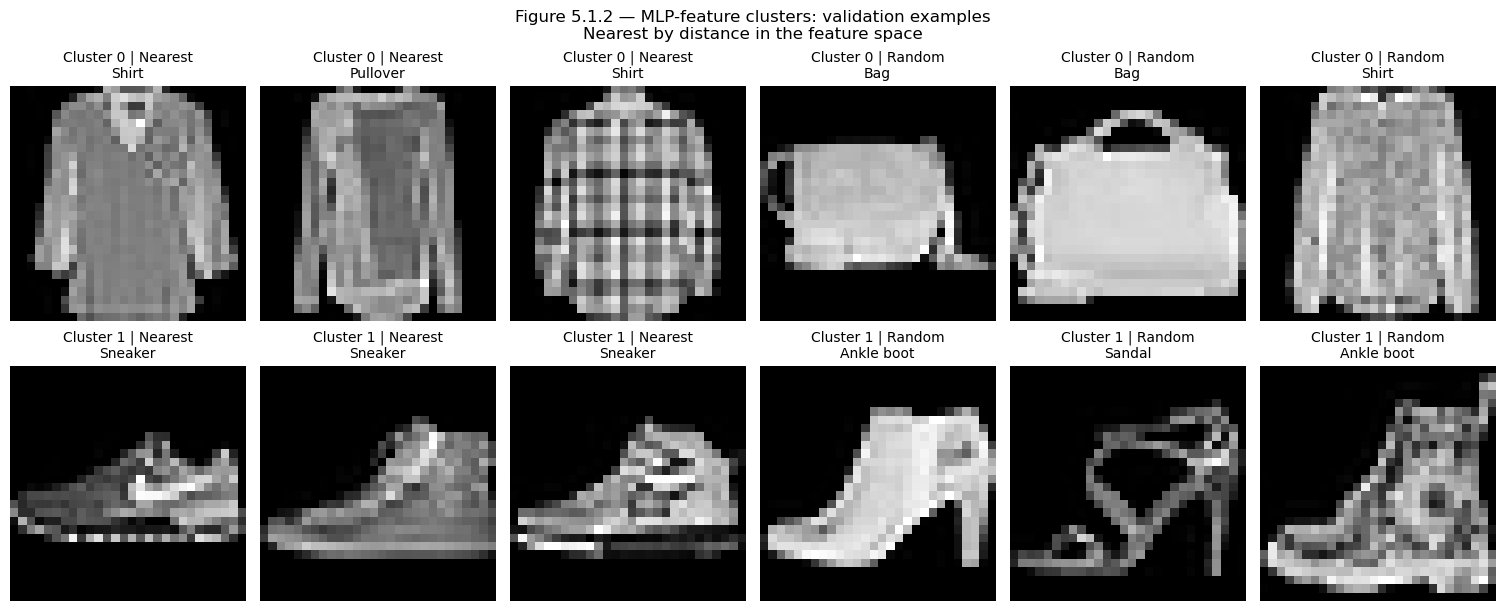

In [71]:
#checking examples from MCP feature clusters
feature_distances = mlp_kmeans_selected.transform(mlp_val_features)
example_rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 6, figsize=(15, 6), layout="constrained")
for cluster in range(2):
    members = np.flatnonzero(mlp_assignments == cluster)
    nearest = members[np.argsort(feature_distances[members, cluster])[:3]]
    remaining = np.setdiff1d(members, nearest)
    random_members = example_rng.choice(remaining,size=min(3, len(remaining)),replace=False,)

    for ax in axes[cluster]:
        ax.axis("off")
    for start_column, positions, method in [(0, nearest, "Nearest"),(3, random_members, "Random"),]:
        for offset, pos in enumerate(positions):
            ax = axes[cluster, start_column + offset]
            # display the exact image corresponding to this feature row.
            ax.imshow(raw_val[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
            ax.set_title(f"Cluster {cluster} | {method}\n"
                f"{class_names[int(true_feature_val[pos])]}",fontsize=10,)
fig.suptitle("Figure 5.1.2 — MLP-feature clusters: validation examples\n" "Nearest by distance in the feature space")
fig.savefig(part5_1_dir / "feature_cluster_examples.png",dpi=150,bbox_inches="tight",)
plt.show()

<b> ** 5.1 - Comparison Analysis ** </b>
* With the same images and K=2, MLP features gave clearer separation. The footwear cluster contained all 300 footwear images and only three body-clothing images, compared with 287 and 156 using raw pixels.
* Silhouette increased from 0.1887 to 0.3360. Bags remained split: 55 in the clothing cluster and 45 in the footwear cluster.
* The examples show shirts and pullovers grouped together, and different footwear types sharing one cluster.
* K-means used no labels, but the MLP learned from labelled data. The improvement therefore relies on supervised features.

In [72]:
#extracting featues from the same 200 images (combine with below cell?!)
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

# copying the exact ordered indices used in Part 4.4.
comparison_hierarchy_indices = np.asarray(hierarchy_indices, dtype=int).copy()
hierarchy_raw_pixels = (images[comparison_hierarchy_indices].astype(np.float32).reshape(200, -1) / 255.0)
hierarchy_mlp_features = extract_hidden_features(hierarchy_raw_pixels)
hierarchy_true_labels = np.asarray(classes)[comparison_hierarchy_indices]

print("Images:", len(comparison_hierarchy_indices))
print("Raw-pixel shape:", hierarchy_raw_pixels.shape)
print("MLP-feature shape:", hierarchy_mlp_features.shape)

Images: 200
Raw-pixel shape: (200, 784)
MLP-feature shape: (200, 256)


In [73]:
#recreating the raw-pixel hierarchy using the same pixel conversion from 4.4 above
hierarchy_representations = {"Raw pixels": (images[comparison_hierarchy_indices]
        .astype(np.float64).reshape(200, -1) / 255.0),
    "MLP features": hierarchy_mlp_features.astype(np.float64),}

comparison_linkages = {}
comparison_cuts = {}
for name, features in hierarchy_representations.items():
    linkage_matrix = linkage(features,method="ward",metric="euclidean",optimal_ordering=False,)
    comparison_linkages[name] = linkage_matrix
    comparison_cuts[name] = cut_tree(linkage_matrix, n_clusters=[2, 4])

    print(f"\n{name}")
    print("Two-group sizes:",np.bincount(comparison_cuts[name][:, 0]),)
    print("Four-group sizes:",np.bincount(comparison_cuts[name][:, 1]),)


Raw pixels
Two-group sizes: [ 81 119]
Four-group sizes: [28 49 53 70]

MLP features
Two-group sizes: [ 56 144]
Four-group sizes: [56 36 35 73]


In [74]:
#comparing group composition
for name, cuts in comparison_cuts.items():
    for column, k in enumerate([2, 4]):
        groups = cuts[:, column]

        counts = pd.crosstab(
            pd.Series(groups, name="Group"),
            pd.Series(hierarchy_true_labels, name="Class"),).reindex(
            index=range(k),columns=range(len(class_names)),fill_value=0,)
        counts.columns = pd.Index(class_names, name="Class")
        composition_pct = counts.div(counts.sum(axis=1), axis=0) * 100
        counts.to_csv(part5_1_dir / f"class_counts_k{k}.csv")
        composition_pct.to_csv(part5_1_dir / f"composition_percent_k{k}.csv")

        print(f"\n{name}: class counts at {k} groups")
        print(counts.to_string())
        print(f"\n{name}: composition within each group (%)")
        print(composition_pct.round(1).to_string())

    print(f"\n{name}: four-group branches within two-group parents")
    print(pd.crosstab(
            pd.Series(cuts[:, 1], name="Four-group branch"),
            pd.Series(cuts[:, 0], name="Two-group parent"),).to_string())
    nested = pd.crosstab(
    pd.Series(groups_4, name="Four-group branch"),
    pd.Series(groups_2, name="Two-group parent"),)
    nested.to_csv(part5_1_dir/ "nested_groups.csv")



Raw pixels: class counts at 2 groups
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                                                                      
0                2        1         5      0     4      18      4       20    9          18
1               24       17        12     19    19       0     19        0    9           0

Raw pixels: composition within each group (%)
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker   Bag  Ankle boot
Group                                                                                       
0              2.5      1.2       6.2    0.0   4.9    22.2    4.9     24.7  11.1        22.2
1             20.2     14.3      10.1   16.0  16.0     0.0   16.0      0.0   7.6         0.0

Raw pixels: class counts at 4 groups
Class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  Sneaker  Bag  Ankle boot
Group                                        

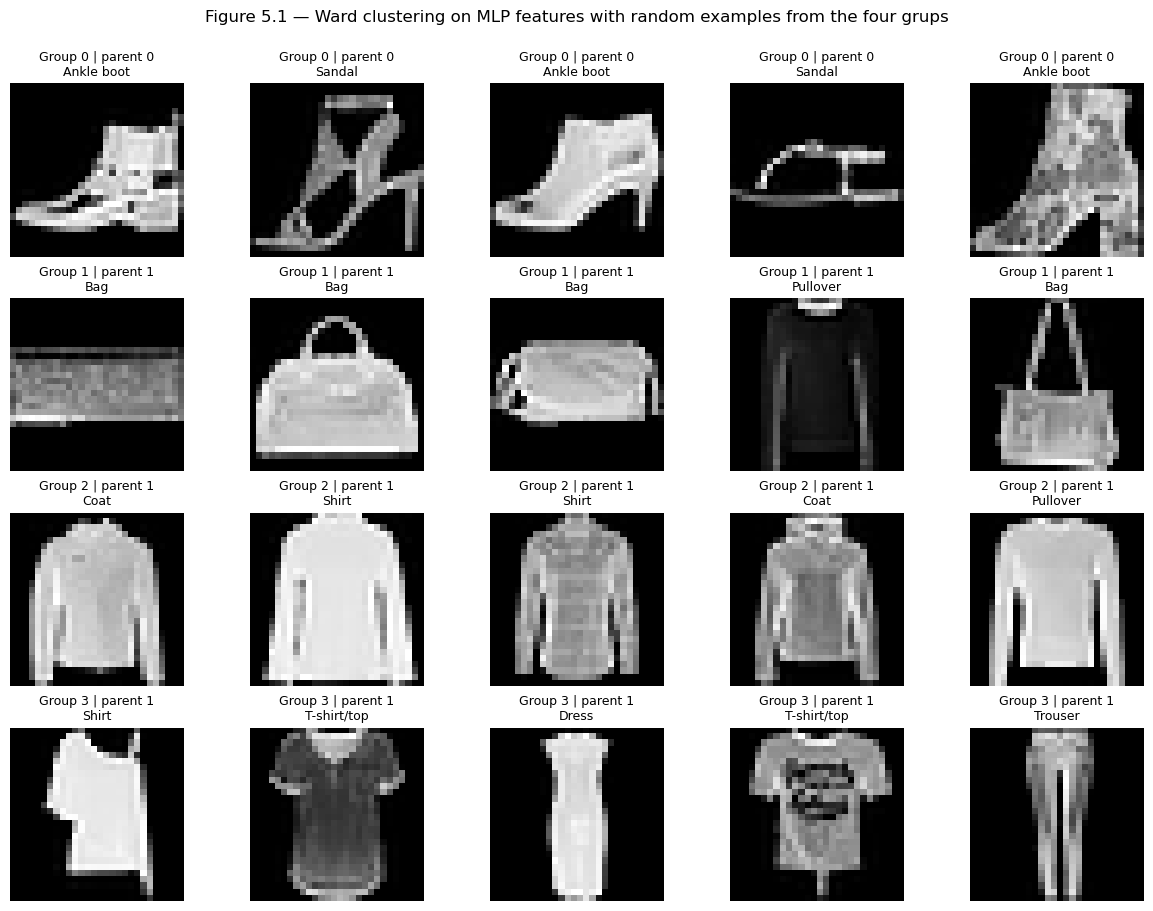

In [75]:
#now checking the images from this learned-feature hierarchy
mlp_hierarchy_groups_2 = comparison_cuts["MLP features"][:, 0]
mlp_hierarchy_groups_4 = comparison_cuts["MLP features"][:, 1]

example_rng = np.random.default_rng(42)
fig, axes = plt.subplots(4, 5, figsize=(12, 9), layout="constrained")
for group in range(4):
    members = np.flatnonzero(mlp_hierarchy_groups_4 == group)
    chosen = example_rng.choice(members, size=min(5, len(members)), replace=False)
    for ax in axes[group]:
        ax.axis("off")
    for column, pos in enumerate(chosen):
        ax = axes[group, column]
        # Use the same position for image, group and true label.
        ax.imshow(hierarchy_raw_pixels[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
        parent = int(mlp_hierarchy_groups_2[pos])
        label = class_names[int(hierarchy_true_labels[pos])]
        ax.set_title(f"Group {group} | parent {parent}\n{label}",fontsize=9,)

fig.suptitle("Figure 5.1 — Ward clustering on MLP features with random examples from the four grups\n")
fig.savefig(part5_1_dir / "ward_cluster_examples.png",dpi=150,bbox_inches="tight",)
plt.show()


<b> ** 5.1 Hierarchy Interpretation ** </b>
* MLP features separated all 56 footwear images from the other 144 images. The raw pixel footwear group also contained 25 non footwear items.
* At four groups, footwear stayed together while the other branch split into three. All 18 bags entered one group, but made up only half its members.
* Figure 5.1 shows varied footwear together and coats, shirts and pullovers sharing another group. * The hierarchy still mixes labelled classes.

In [76]:
exp_frozen_mlp = { "id": "P5_1-FROZEN_MLP_FEATURES-01",
    "question": "Does replacing raw pixels with MLP features change clustering, stability and class composition?",
    "hypothesis": "Classification-trained features may improve broad grouping",
    "changed_variable": "Images: 784 scaled pixels versus 256 frozen post-ReLU hidden activations.",
    "fixed_conditions": (
        "Same images, K-search grid, K-means settings, seeds and selection "
        "rule. Main comparison at K=2. Ward uses the same 200 images, "
        "linkage and two-/four-group cuts."),
    "split":"K-means: 3,000 training and 1,000 validation images. Ward: fixed 200-image training subset.",
    "seed": ("mlp_training_seed: 42; kmeans_seeds: [42, 43, 44]; "
        f"selected_feature_kmeans_seed: {int(mlp_selected_seed)}; "
        "hierarchy_subset_seed: 42; example_sampling_seed: 42"),
    "configuration": ( f"checkpoint: {str(checkpoint_path)}; "
        f"checkpoint_epoch: {int(checkpoint["epoch"])}; "
        f"hidden_units: {int(checkpoint["width"])}; "
        f"training_dropout: {float(checkpoint["dropout"])}; "
        f"training_learning_rate: {float(checkpoint["lr"])}; "
        "training_epoch_budget: 500; extraction_point: After hidden ReLU, before dropout/output; "
        "frozen:eval mode; requires_grad=False; inference_mode "
        "feature_transformation: None; K_values: [2, 4, 6, 8, 10, 12, 15, 20]; "
        "search_init: k-means++; search_n_init: 10; max_iter: 300; tol: 1e-4; "
        "algorithm: lloyd; copy_x: True; stability_init: [random, k-means++]; "
        "stability_n_init: [1, 10]; main_comparison_K: 2; "
        "hierarchy: {method: Ward,metric:Euclidean,optimal_ordering:False,cuts: [2, 4]}"),
    "metric": "validation silhouette; pairwise assignment ARI across seeds; class composition; ",
    "result":("footwear_dominated_cluster:{ "
                "raw:{size: 508,footwear: 287,body_clothing: 156, bags: 65}; "
            "ward_interpretation:( "
            "All 56 footwear images form an unmixed branch. "
            "At four groups, the non-footwear branch splits into three. "
            "All 18 bags enter one 36-image subgroup); "
            "conclusion: Learned features improve broad clothing-footwear separation"),
    "output_path": (f"mlp_checkpoint: {str(checkpoint_path)}; "
        f"clustering_indices: {str(part4_dir / "used_indices.json")}" ),}

register_path = Path("results/experiment_register.csv")
register_path.parent.mkdir(parents=True, exist_ok=True)
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_frozen_mlp])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

print(exp_frozen_mlp["result"])

footwear_dominated_cluster:{ raw:{size: 508,footwear: 287,body_clothing: 156, bags: 65}; ward_interpretation:( All 56 footwear images form an unmixed branch. At four groups, the non-footwear branch splits into three. All 18 bags enter one 36-image subgroup); conclusion: Learned features improve broad clothing-footwear separation


<b>  ** 5.2 - Route B : ensembling : My  plan ** </b>
* Combine the three dropout MLPs from Part 3, using seeds 42, 43 and 44, to test whether averaging reduces errors.
* Keep the 784 - 256 - 10 architecture and validation-selected checkpoints.
* Average their class probabilities with equal weights of 1/3, then predict the class with the highest average probability

In [77]:
#loading the three models from part-3
from time import perf_counter

ensemble_seeds = [42, 43, 44]
ensemble_models = {}
ensemble_checkpoint_records = []
for seed in ensemble_seeds:
    path = Path(f"results/part3/P3-w256-e500-l0.01-dropout-seed{seed}.pt")
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)

    model = RegularisedMLP(width=checkpoint["width"],dropout=checkpoint["dropout"],)
    model.load_state_dict(checkpoint["model_state"])
    model = model.to(device)
    model.eval()
    model.requires_grad_(False)

    ensemble_models[seed] = model
    ensemble_checkpoint_records.append({"seed": seed,"checkpoint": str(path),
        "selected_epoch": int(checkpoint["epoch"]),
        "parameters": sum(p.numel() for p in model.parameters()),
        "checkpoint_bytes": path.stat().st_size,})
ensemble_checkpoints = pd.DataFrame(ensemble_checkpoint_records)
print(ensemble_checkpoints.to_string(index=False))
#getting the validation probabilities
ensemble_val_pixels = (images[val_index].astype(np.float32).reshape(len(val_index), -1) / 255.0)
ensemble_val_targets = np.asarray(classes)[val_index]

def synchronise_device():
    if torch.device(device).type == "cuda":
        torch.cuda.synchronize(device)

def predict_probabilities(model, pixels, batch_size=256):
    model.eval()
    outputs = []
    for start in range(0, len(pixels), batch_size):
        batch = torch.from_numpy(pixels[start:start + batch_size]).to(device)
        probabilities = torch.softmax(model(batch), dim=1)
        outputs.append(probabilities.cpu().numpy())
    return np.concatenate(outputs, axis=0)
member_val_probabilities = {}
member_val_seconds = {}

for seed, model in ensemble_models.items():
    # apparently (from internet research) that a mall warm-up before timing is better
    predict_probabilities(model, ensemble_val_pixels[:256])
    synchronise_device()
    start = perf_counter()
    probabilities = predict_probabilities(model, ensemble_val_pixels)
    synchronise_device()
    member_val_seconds[seed] = perf_counter() - start
    member_val_probabilities[seed] = probabilities
start = perf_counter()
ensemble_val_probabilities = np.mean(np.stack([member_val_probabilities[seed]
        for seed in ensemble_seeds]),axis=0,)
averaging_seconds = perf_counter() - start

ensemble_val_seconds = sum(member_val_seconds.values()) + averaging_seconds

 seed                                         checkpoint  selected_epoch  parameters  checkpoint_bytes
   42 results/part3/P3-w256-e500-l0.01-dropout-seed42.pt             451      203530            817249
   43 results/part3/P3-w256-e500-l0.01-dropout-seed43.pt             482      203530            817249
   44 results/part3/P3-w256-e500-l0.01-dropout-seed44.pt             497      203530            817249


In [78]:
#compare overall validation performance
from sklearn.metrics import accuracy_score, f1_score, log_loss

part5_2_dir = Path("results/part5_2")
part5_2_dir.mkdir(parents=True, exist_ok=True)
validation_probabilities = {f"MLP seed {seed}": member_val_probabilities[seed]
    for seed in ensemble_seeds}
validation_probabilities["Ensemble"] = ensemble_val_probabilities
validation_predictions = {}
validation_records = []

for name, probabilities in validation_probabilities.items():
    predictions = probabilities.argmax(axis=1)
    validation_predictions[name] = predictions
    if name == "Ensemble":
        seconds = ensemble_val_seconds
    else:
        seed = int(name.split()[-1])
        seconds = member_val_seconds[seed]
    validation_records.append({"model": name,"accuracy": accuracy_score(
            ensemble_val_targets, predictions),
        "macro_f1": f1_score(ensemble_val_targets,predictions,labels=range(len(class_names)),
            average="macro",zero_division=0,),
        "cross_entropy": log_loss(ensemble_val_targets,probabilities,labels=range(len(class_names)),),
        "errors": int(np.sum(predictions != ensemble_val_targets)),
        "prediction_seconds": seconds,})

ensemble_validation_summary = pd.DataFrame(validation_records)
ensemble_validation_summary.to_csv(part5_2_dir / "ensemble_validation.csv", index=False)
print(ensemble_validation_summary.round(4).to_string(index=False))

      model  accuracy  macro_f1  cross_entropy  errors  prediction_seconds
MLP seed 42    0.8759    0.8755         0.3540    1241              0.0631
MLP seed 43    0.8756    0.8749         0.3563    1244              0.0710
MLP seed 44    0.8757    0.8753         0.3561    1243              0.0169
   Ensemble    0.8756    0.8752         0.3483    1244              0.1518


In [79]:
#compare the effect at each class-level, there may also be new errors
from sklearn.metrics import precision_recall_fscore_support

class_records = []
for name, predictions in validation_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        ensemble_val_targets,predictions,labels=range(len(class_names)),zero_division=0,)
    for class_id, class_name in enumerate(class_names):
        class_records.append({"model": name,"class": class_name,"precision": precision[class_id],
            "recall": recall[class_id],"f1": f1[class_id],"support": int(support[class_id]),})

ensemble_class_results = pd.DataFrame(class_records)
ensemble_class_results.to_csv(part5_2_dir / "validation_by_class.csv", index=False)

print("\nValidation recall by class")
print(ensemble_class_results.pivot(index="class", columns="model", values="recall"
    ).reindex(class_names).round(4).to_string())
print("\nValidation F1 by class")
print(ensemble_class_results.pivot(index="class", columns="model", values="f1"
    ).reindex(class_names).round(4).to_string())

ensemble_correct = (validation_predictions["Ensemble"] == ensemble_val_targets)
change_records = []
for seed in ensemble_seeds:
    member_correct = (validation_predictions[f"MLP seed {seed}"] == ensemble_val_targets)
    corrected = int(np.sum(~member_correct & ensemble_correct))
    introduced = int(np.sum(member_correct & ~ensemble_correct))
    change_records.append({ "compared_with": f"MLP seed {seed}","errors_corrected": corrected,
        "new_errors_introduced": introduced,"net_additional_correct": corrected - introduced,
        "accuracy_gain_pp": (100 * (corrected - introduced) / len(ensemble_val_targets)),})

ensemble_error_changes = pd.DataFrame(change_records)
ensemble_error_changes.to_csv(part5_2_dir / "error_changes.csv", index=False)
print("\nEnsemble corrections and new errors")
print(ensemble_error_changes.round(3).to_string(index=False))

single_parameters = int(ensemble_checkpoints.iloc[0]["parameters"])
total_parameters = int(ensemble_checkpoints["parameters"].sum())
print("\nResource cost")
print("Single-model parameters:", single_parameters)
print("Ensemble parameters:", total_parameters)
print("Forward passes per image: 1 for a member; 3 for the ensemble")
print("Additional training for this extension: none")
print("Combined checkpoint size:",
    f"{ensemble_checkpoints['checkpoint_bytes'].sum() / 1024**2:.2f} MiB")



Validation recall by class
model        Ensemble  MLP seed 42  MLP seed 43  MLP seed 44
class                                                       
T-shirt/top     0.847        0.843        0.857        0.843
Trouser         0.971        0.970        0.970        0.971
Pullover        0.808        0.808        0.809        0.808
Dress           0.882        0.888        0.888        0.878
Coat            0.791        0.789        0.798        0.802
Sandal          0.945        0.943        0.943        0.946
Shirt           0.667        0.666        0.651        0.672
Sneaker         0.926        0.935        0.929        0.916
Bag             0.958        0.958        0.955        0.957
Ankle boot      0.961        0.959        0.956        0.964

Validation F1 by class
model        Ensemble  MLP seed 42  MLP seed 43  MLP seed 44
class                                                       
T-shirt/top    0.8365       0.8347       0.8353       0.8342
Trouser        0.9764       0.975

<b> ** 5.2 - Interim analysis ** </b>
* Ensemble validation accuracy is 87.56%, with no gain over the members. Compared with seed 42, it corrected 85 errors but introduced 88.

Corrected by ensemble: 85 validation images
New error from ensemble: 88 validation images


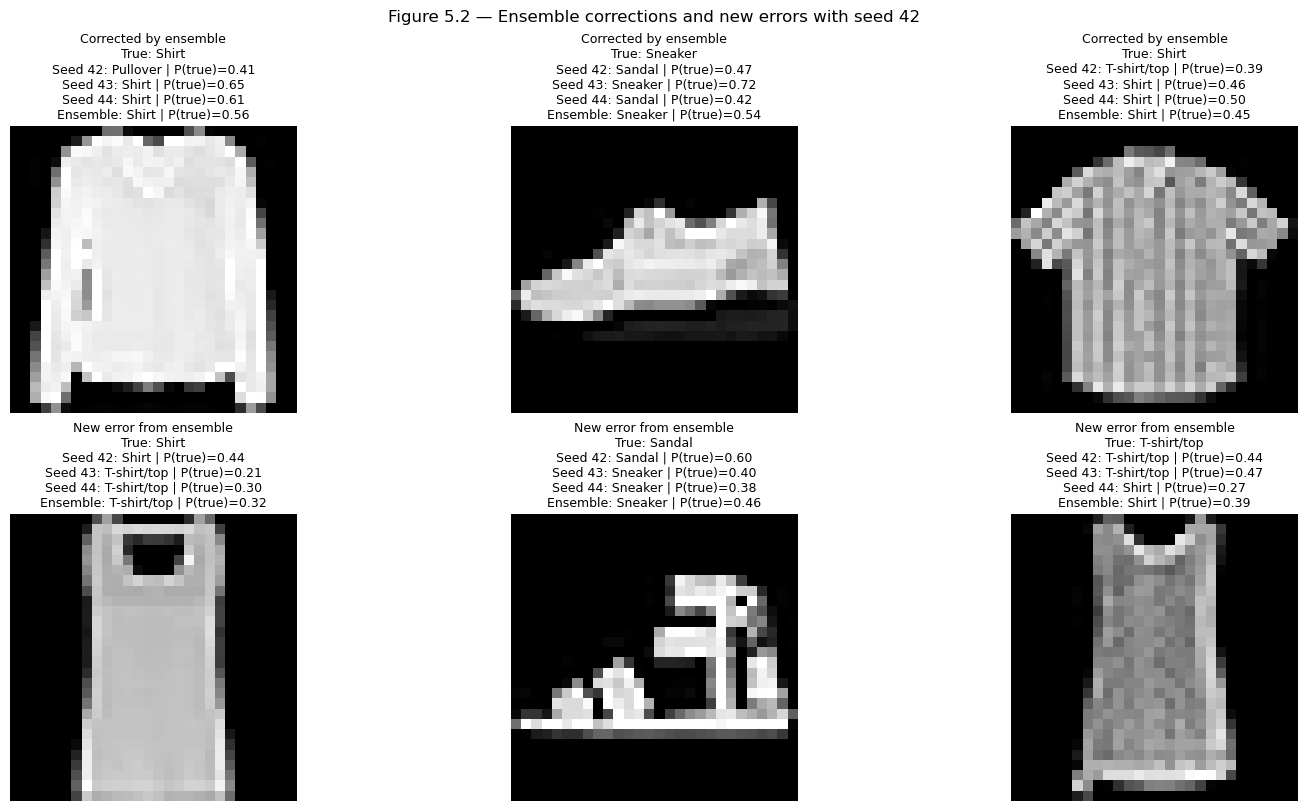

In [80]:
#checking out the correct and the newly added errors for information
reference_name = "MLP seed 42"
reference_predictions = validation_predictions[reference_name]
ensemble_predictions = validation_predictions["Ensemble"]
reference_correct = (reference_predictions == ensemble_val_targets)
ensemble_correct = (ensemble_predictions == ensemble_val_targets)

example_groups = [("Corrected by ensemble", ~reference_correct & ensemble_correct),
    ("New error from ensemble", reference_correct & ~ensemble_correct),]
rng = np.random.default_rng(42)
example_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for row, (outcome, mask) in enumerate(example_groups):
    positions = np.flatnonzero(mask)
    chosen = rng.choice(positions, size=min(3, len(positions)), replace=False)
    print(f"{outcome}: {len(positions)} validation images")

    for ax in axes[row]:
        ax.axis("off")
    for ax, pos in zip(axes[row], chosen):
        true_id = int(ensemble_val_targets[pos])
        ax.imshow(ensemble_val_pixels[pos].reshape(28, 28),cmap="gray",vmin=0,vmax=1,)
        prediction_lines = []
        for name, probabilities in validation_probabilities.items():
            predicted_id = int(probabilities[pos].argmax())
            p_true = float(probabilities[pos, true_id])
            short_name = name.replace("MLP seed ", "Seed ")
            prediction_lines.append(f"{short_name}: {class_names[predicted_id]}"
                f" | P(true)={p_true:.2f}")
            example_rows.append({"outcome": outcome,"validation_position": int(pos),
                "original_image_index": int(val_index[pos]),
                "true_class": class_names[true_id], "model": name,
                "predicted_class": class_names[predicted_id],
                "probability_true_class": p_true,
                "probability_predicted_class": float(probabilities[pos, predicted_id]),})
        ax.set_title(f"{outcome}\nTrue: {class_names[true_id]}\n"+ "\n".join(prediction_lines),fontsize=9,)

fig.suptitle("Figure 5.2 — Ensemble corrections and new errors with seed 42")
fig.savefig(part5_2_dir / "ensemple_examples.png",dpi=150,bbox_inches="tight",)
plt.show()

ensemble_example_details = pd.DataFrame(example_rows)
ensemble_example_details.to_csv(part5_2_dir / "ensemble_examples.csv",index=False)

<b> Figure 5.2 - Interim analysis ** </b>
* Figure 5.2 shows both corrections and new errors compared with seed 42. There is still confusion between shirts and similar clothing, and between footwear classes.

In [81]:
#evaluate all three models and the ensemble on the official 10,000 image test set
#load the test set images finallu now
from torchvision.datasets import FashionMNIST

ensemble_test_dataset = FashionMNIST(root="./data",train=False,download=True,)
ensemble_test_pixels = (ensemble_test_dataset.data.numpy().astype(np.float32).reshape(-1, 784) / 255.0)
ensemble_test_targets = ensemble_test_dataset.targets.numpy()

print("Test images:", len(ensemble_test_targets))
print("Input shape:", ensemble_test_pixels.shape)
print("Ensemble seeds:", ensemble_seeds)
print("Combination rule: equal-weight mean of class probabilities")

#generate test predictions
member_test_probabilities = {}
member_test_seconds = {}
for seed in ensemble_seeds:
    model = ensemble_models[seed]
    # Warm-up forward pass like before, without training or parameter updates.
    predict_probabilities(model, ensemble_test_pixels[:256])
    synchronise_device()
    start = perf_counter()
    probabilities = predict_probabilities(model, ensemble_test_pixels)
    synchronise_device()
    member_test_seconds[seed] = perf_counter() - start
    member_test_probabilities[seed] = probabilities

start = perf_counter()
ensemble_test_probabilities = np.mean(np.stack([member_test_probabilities[seed]
        for seed in ensemble_seeds]),axis=0,)
test_averaging_seconds = perf_counter() - start
ensemble_test_seconds = (sum(member_test_seconds.values()) + test_averaging_seconds)
test_probabilities = {f"MLP seed {seed}": member_test_probabilities[seed]
    for seed in ensemble_seeds}
test_probabilities["Ensemble"] = ensemble_test_probabilities

Test images: 10000
Input shape: (10000, 784)
Ensemble seeds: [42, 43, 44]
Combination rule: equal-weight mean of class probabilities


In [82]:
#overall test result and validation comparison
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, f1_score, log_loss

test_predictions = {}
test_records = []
for name, probabilities in test_probabilities.items():
    predictions = probabilities.argmax(axis=1)
    test_predictions[name] = predictions
    if name == "Ensemble":
        seconds = ensemble_test_seconds
    else:
        seed = int(name.split()[-1])
        seconds = member_test_seconds[seed]
    test_records.append({"model": name,"accuracy": accuracy_score(
            ensemble_test_targets, predictions),
        "macro_f1": f1_score(ensemble_test_targets,predictions,labels=range(len(class_names)),
            average="macro",zero_division=0,),
        "cross_entropy": log_loss(ensemble_test_targets,probabilities,
            labels=range(len(class_names)),),
        "errors": int(np.sum(predictions != ensemble_test_targets)),
        "prediction_seconds": seconds,})

ensemble_test_summary = pd.DataFrame(test_records)
ensemble_test_summary.to_csv(part5_2_dir / "ensemble_test.csv", index=False)
print("Final test results")
print(ensemble_test_summary.round(4).to_string(index=False))
validation_test_comparison = (ensemble_validation_summary[
        ["model", "accuracy", "macro_f1", "cross_entropy"]].merge(
        ensemble_test_summary[["model", "accuracy", "macro_f1", "cross_entropy"]],
        on="model",suffixes=("_validation", "_test"),validate="one_to_one",))

val_test_compare_summary = pd.DataFrame(validation_test_comparison)
val_test_compare_summary.to_csv(part5_2_dir / "val_test_comparision.csv", index=False)
print("\nValidation and test comparison")
print(validation_test_comparison.round(4).to_string(index=False))

#class-level test results and changed (e.g., corrected/new) errors
test_class_records = []
for name, predictions in test_predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        ensemble_test_targets,predictions,labels=range(len(class_names)),zero_division=0,)
    for class_id, class_name in enumerate(class_names):
        test_class_records.append({"model": name,"class": class_name,
            "precision": precision[class_id],"recall": recall[class_id],
            "f1": f1[class_id],"support": int(support[class_id]),})
ensemble_test_class_results = pd.DataFrame(test_class_records)
ensemble_test_class_results.to_csv(part5_2_dir / "ensemble_test_byclass.csv", index=False)
for metric in ["precision", "recall", "f1"]:
    print(f"\nTest {metric} by class")
    print(ensemble_test_class_results.pivot(index="class", columns="model", values=metric
        ).reindex(class_names).round(4).to_string())
ensemble_test_correct = (test_predictions["Ensemble"] == ensemble_test_targets)
test_change_records = []

for seed in ensemble_seeds:
    member_correct = (test_predictions[f"MLP seed {seed}"]== ensemble_test_targets)
    corrected = int(np.sum(~member_correct & ensemble_test_correct))
    introduced = int(np.sum(member_correct & ~ensemble_test_correct))
    test_change_records.append({"compared_with": f"MLP seed {seed}",
        "errors_corrected": corrected,"new_errors_introduced": introduced,
        "net_additional_correct": corrected - introduced,
        "accuracy_gain_pp": (100 * (corrected - introduced)/ len(ensemble_test_targets)),})

ensemble_test_error_changes = pd.DataFrame(test_change_records)
ensemble_test_error_changes.to_csv(part5_2_dir / "emsemble_test_errors.csv", index=False)
print("\nTest corrections and new errors")
print(ensemble_test_error_changes.round(3).to_string(index=False))

Final test results
      model  accuracy  macro_f1  cross_entropy  errors  prediction_seconds
MLP seed 42    0.8612    0.8603         0.4045    1388              0.0193
MLP seed 43    0.8600    0.8589         0.4049    1400              0.0292
MLP seed 44    0.8605    0.8601         0.4084    1395              0.0351
   Ensemble    0.8632    0.8624         0.3979    1368              0.0845

Validation and test comparison
      model  accuracy_validation  macro_f1_validation  cross_entropy_validation  accuracy_test  macro_f1_test  cross_entropy_test
MLP seed 42               0.8759               0.8755                    0.3540         0.8612         0.8603              0.4045
MLP seed 43               0.8756               0.8749                    0.3563         0.8600         0.8589              0.4049
MLP seed 44               0.8757               0.8753                    0.3561         0.8605         0.8601              0.4084
   Ensemble               0.8756               0.8752 

<b> ** 5.2 - Final Analysis ** </b>
* Ensemble test accuracy reached 86.32%, compared with 86.00% to 86.12% for individual models. It also achieved the best macro-F1 (0.8624) and cross-entropy (0.3979).
* Compared with seed 42, it corrected 111 errors but introduced 91: a net gain of 20 images
* Class-level gains were mixed. Shirt remained hardest, with 60.9% recall;
* Validation accuracy did not improve, but test accuracy did.
* The ensemble required three forward passes and three times the parameters. Prediction took about 2.8 times longer than seed 42.
* The test gain was small relative to the extra cost

<b> **  5.2 - Comparison of the  three routes ** </b>
* Frozen pre-trained features: reuse an external encoder without updating it. Requires pre-training knowledge, storage and feature-extraction compute.
* Ensembling (which I did): averages predictions from several models. Requires extra model storage and forward passes.
* Test-time augmentation: averages predictions across transformed images. Requires image transformations and extra forward passes.

<b> ** 5.2 - Under a fixed budget, what would I investigate next, and why? ** 
* I would investigate test-time augmentation next, i.e. , one model could process the original image and two small, fixed translations, reducing model storage compared with this ensemble
* My hypothesis would be that sensitivity to image position contributes to some errors. I would select the transformation policy using validation data and compare class-level effects and runtime against the unaugmented model.
* This would let me test whether test-time augmentation improves on the single model or ensemble, considering both accuracy and inference cost

<b> ** Part 6 - Final Synthesis ** </b>

1. Observation: Shirt remained difficult across classifiers and the final ensemble. Clustering grouped shirts with commonly confused garments. Interpretation: shared visual patterns may contribute to errors, but grouping does not show the cause. [Tasks 1.3, 4.2–4.3 and 5.2: class tables and examples]
2. Observation: Wider networks improved training fit more than validation accuracy. Learning rate also affected progress and stability. Conclusion: capacity must be considered along with  optimisation and training budget. [Figures 2.2–2.3]
3. Observation: Dropout improved validation accuracy across all three seeds. Unregularised training showed late overfitting. Conclusion: dropout helped, although three seeds provide limited evidence of reliability. [Tasks 3.1–3.2: curves and checkpoint tables]
4. Observation: With images and clustering settings fixed, learned features reduced body-clothing images in the footwear cluster from 156 to 3. Interpretation: supervised features improved broad separation, but did not recover ten distinct classes. [Tasks 4.2 and 5.1: heatmaps and examples]
5. Conclusion: Ensembling provided a small return for extra cost: 20 additional correct test predictions over seed 42, requiring three forward passes. Validation accuracy did not improve, so the benefit was not consistent across splits. [Task 5.2: results and cost tables]
6. Hypothesis: More ensemble models may give diminishing gains when their errors overlap. I would compare one, three and five members across seed groups, measuring errors and cost. [Tasks 3.2 and 5.2; not tested]